# Avance 2: Ejecución y análisis
**Tema del proyecto:** Salud hospitalaria — Egresos Hospitalarios y Estadía Hospitalaria Prolongada (EHP) en Chile  
**Hito:** Avance 2 (20%) — Ejecución y análisis

## 1. Exploración y preparación de datos

In [1]:

# CARGA DE LA BASE DE DATOS DE EGRESOS HOSPITALARIOS Y PREPARACIÓN DE VARIABLES

import pandas as pd
import numpy as np
import os
import re

RUTA_ARCHIVO_EGRESOS = "EGR_DATOS_ABIERTO_2025.csv"
if not os.path.exists(RUTA_ARCHIVO_EGRESOS):
    raise FileNotFoundError(f"No se encontró '{RUTA_ARCHIVO_EGRESOS}'. Súbelo a Colab.")

# 1. Lectura de la base completa
df = pd.read_csv(RUTA_ARCHIVO_EGRESOS, sep=";", encoding="utf-8", low_memory=False)
n0 = len(df)

# Etiquetas de edad: el archivo original trae un carácter inválido en dos tramos
df["GRUPO_EDAD"] = df["GRUPO_EDAD"].replace({"menor de un a\ufffdo": "menor de un año", "90 y m\ufffds": "90 y más"})

# 2. Limpieza
df["DIAS_ESTADA"] = pd.to_numeric(df["DIAS_ESTADA"], errors="coerce")
df = df.dropna(subset=["DIAS_ESTADA", "GRUPO_EDAD", "GLOSA_PREVISION",
                       "PERTENENCIA_ESTABLECIMIENTO_SALU"])
df = df[df["DIAS_ESTADA"] > 0]
df = df[(df["GRUPO_EDAD"] != "*") &
        (~df["GLOSA_PREVISION"].isin(["*", "DESCONOCIDO"]))]
n1 = len(df)

# 3. Umbral EHP (P75) calculado sobre toda la base limpia
p75_estadia = np.percentile(df["DIAS_ESTADA"], 75)

# 4. Muestra aleatoria reproducible de 1.000.000 de egresos
df = df.sample(n=1_000_000, random_state=42).reset_index(drop=True)

# 5. Variable respuesta
df["ESTADIA_PROLONGADA_BIN"] = (df["DIAS_ESTADA"] > p75_estadia).astype(int)
df["ESTADIA_PROLONGADA"] = np.where(df["DIAS_ESTADA"] > p75_estadia,
                                    f"Prolongada (> {p75_estadia:.0f}d)",
                                    f"Normal (<= {p75_estadia:.0f}d)")

# 6. Edad aproximada (marca de clase del tramo)
def extraer_marca_edad(valor):
    s = str(valor).lower()
    if "menor" in s:
        return 0.5
    nums = [int(n) for n in re.findall(r"\d+", s)]
    if len(nums) >= 2:
        return (nums[0] + nums[1]) / 2.0
    elif len(nums) == 1:
        return float(nums[0]) + 5.0
    return np.nan

df["EDAD_APROX"] = df["GRUPO_EDAD"].apply(extraer_marca_edad)

# 7. Resumen
print("=" * 75)
print("RESUMEN DEL DATASET CARGADO")
print("=" * 75)
print(f"Registros en la base original      : {n0:,}")
print(f"Tras limpieza (sin '*'/desconocido): {n1:,}")
print(f"Muestra aleatoria analizada (N)    : {len(df):,}")
print(f"Media de DIAS_ESTADA               : {df['DIAS_ESTADA'].mean():.2f} días")
print(f"Mediana de DIAS_ESTADA             : {df['DIAS_ESTADA'].median():.2f} días")
print(f"Percentil 75 (umbral EHP)          : {p75_estadia:.2f} días")
print(f"Desviación estándar                : {df['DIAS_ESTADA'].std():.2f} días")
print(f"Asimetría (skewness)               : {df['DIAS_ESTADA'].skew():.2f}")
print(f"Proporción estadía prolongada      : {df['ESTADIA_PROLONGADA_BIN'].mean()*100:.2f}%")

RESUMEN DEL DATASET CARGADO
Registros en la base original      : 1,705,514
Tras limpieza (sin '*'/desconocido): 1,576,792
Muestra aleatoria analizada (N)    : 1,000,000
Media de DIAS_ESTADA               : 6.13 días
Mediana de DIAS_ESTADA             : 2.00 días
Percentil 75 (umbral EHP)          : 6.00 días
Desviación estándar                : 40.48 días
Asimetría (skewness)               : 198.13
Proporción estadía prolongada      : 21.65%


In [2]:
#Revisión de variables
vars_modelo = ["SEXO", "GRUPO_EDAD", "GLOSA_PREVISION",
               "PERTENENCIA_ESTABLECIMIENTO_SALU", "DIAG1", "CONDICION_EGRESO"]

print("Filas:", len(df))
for c in vars_modelo:
    print(f"\n--- {c} ---")
    print("Nulos:", df[c].isna().sum())
    print(df[c].value_counts(dropna=False).head(8))


Filas: 1000000

--- SEXO ---
Nulos: 0
SEXO
MUJER                        570566
HOMBRE                       429425
INTERSEX (INDETERMINDADO)         9
Name: count, dtype: int64

--- GRUPO_EDAD ---
Nulos: 0
GRUPO_EDAD
30 a 39    155823
60 a 69    146462
70 a 79    123670
50 a 59    118518
40 a 49    114179
20 a 29    108966
80 a 89     71109
10 a 19     62585
Name: count, dtype: int64

--- GLOSA_PREVISION ---
Nulos: 0
GLOSA_PREVISION
FONASA       795208
ISAPRE       175419
DIPRECA        8597
NINGUNA        8489
CAPREDENA      7226
SISA           5061
Name: count, dtype: int64

--- PERTENENCIA_ESTABLECIMIENTO_SALU ---
Nulos: 0
PERTENENCIA_ESTABLECIMIENTO_SALU
Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS       615878
No Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS    384122
Name: count, dtype: int64

--- DIAG1 ---
Nulos: 0
DIAG1
K358    13754
O800    12424
K802    11710
J189    11364
O820    10388
N390     9808
O829     9785
E669     9324
Name: count, 

In [3]:
#Revisión de variables

print(df["PERTENENCIA_ESTABLECIMIENTO_SALU"].value_counts(dropna=False))
print(df["GLOSA_PREVISION"].value_counts(dropna=False))
print("\nDIAG1 - ejemplos:", df["DIAG1"].dropna().unique()[:15])
print("DIAG1 - categorías distintas:", df["DIAG1"].nunique())
print("DIAG1 - nulos:", df["DIAG1"].isna().sum())
print("DIAG1 - largo del código:\n", df["DIAG1"].astype(str).str.len().value_counts())


PERTENENCIA_ESTABLECIMIENTO_SALU
Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS       615878
No Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS    384122
Name: count, dtype: int64
GLOSA_PREVISION
FONASA       795208
ISAPRE       175419
DIPRECA        8597
NINGUNA        8489
CAPREDENA      7226
SISA           5061
Name: count, dtype: int64

DIAG1 - ejemplos: <StringArray>
['Z518', 'K358', 'J129', 'N47X', 'S451', 'M840', 'K803', 'I800', 'O034',
 'N921', 'N393', 'D122', 'O820', 'K808', 'C679']
Length: 15, dtype: str
DIAG1 - categorías distintas: 6776
DIAG1 - nulos: 0
DIAG1 - largo del código:
 DIAG1
4    1000000
Name: count, dtype: int64


In [4]:
# eliminar INTERSEX y cruzar con el diccionario

# 1) eliminar los 9 egresos con sexo indeterminado
df = df[df["SEXO"] != "INTERSEX (INDETERMINDADO)"].copy()
print("Filas tras quitar sexo indeterminado:", len(df))

# 2) leer la hoja de códigos CIE-10 del diccionario
RUTA_DICC = "Diccionario BD egresos hospitalario.xlsx"   # ajusta si tu archivo se llama distinto
cie = pd.read_excel(RUTA_DICC, sheet_name="codigo CIE-10", header=8)
cie["CODIGO SUBCATEGORIA"] = cie["CODIGO SUBCATEGORIA"].astype(str).str.strip().str.upper()
cie["CODIGO CATEGORIA"]    = cie["CODIGO CATEGORIA"].astype(str).str.strip().str.upper()

# 3) asignar el capítulo
por_sub = cie.drop_duplicates("CODIGO SUBCATEGORIA").set_index("CODIGO SUBCATEGORIA")["GLOSA CAPITULO"]
por_cat = cie.drop_duplicates("CODIGO CATEGORIA").set_index("CODIGO CATEGORIA")["GLOSA CAPITULO"]

cod = df["DIAG1"].astype(str).str.strip().str.upper()
df["CAPITULO_CIE"] = cod.map(por_sub).fillna(cod.str[:3].map(por_cat))

print(f"\nDIAG1 con capítulo asignado: {df['CAPITULO_CIE'].notna().mean():.2%}")
print("Códigos sin capítulo (ejemplos):", df.loc[df['CAPITULO_CIE'].isna(), 'DIAG1'].value_counts().head(10).to_dict())
print("\nEgresos por capítulo:")
print(df["CAPITULO_CIE"].value_counts(dropna=False))

Filas tras quitar sexo indeterminado: 999991



DIAG1 con capítulo asignado: 100.00%
Códigos sin capítulo (ejemplos): {'U109': 12, 'U099': 3, 'A979': 2, 'A970': 2, 'A971': 1}

Egresos por capítulo:
CAPITULO_CIE
Enfermedades del sistema digestivo                                                                                            143628
Embarazo, parto y puerperio                                                                                                   116915
Traumatismos, envenenamientos y algunas otras consecuencias de causas externas                                                 99522
Enfermedades del sistema respiratorio                                                                                          96350
Enfermedades del sistema circulatorio                                                                                          93323
Enfermedades del sistema genitourinario                                                                                        90848
Tumores [Neoplasias]                  

In [5]:
#completar los 20 códigos faltantes
sin_cap = df["CAPITULO_CIE"].isna()
df.loc[sin_cap & df["DIAG1"].str.startswith("U"), "CAPITULO_CIE"] = "Códigos para propósitos especiales"
df.loc[sin_cap & df["DIAG1"].str.startswith("A"), "CAPITULO_CIE"] = "Ciertas enfermedades infecciosas y parasitarias"
print("Capítulos sin asignar:", df["CAPITULO_CIE"].isna().sum())

Capítulos sin asignar: 0


**Decisiones de limpieza**

- **Sexo indeterminado:** se eliminaron 9 egresos con sexo "INTERSEX (INDETERMINADO)" (0,0009% de la muestra). Con tan pocos casos el modelo no puede estimar su efecto y una categoría tan pequeña produciría coeficientes inestables.

- **Valores nulos:** la base no presenta nulos en las variables del estudio, por lo que no fue necesario imputar.

- **Diagnóstico (`DIAG1`):** el diagnóstico principal se toma como la condición de ingreso del paciente. Tiene 6.776 códigos CIE-10 distintos. Se agruparon por capítulo usando la hoja de códigos del diccionario oficial, lo que reduce la variable a 21 categorías interpretables (nueva columna `CAPITULO_CIE`).

- **Códigos sin capítulo en el diccionario:** 20 egresos (0,002%) tenían un `DIAG1` válido, pero su código no figura en el diccionario (U099, U109 y A970–A979), por lo que `CAPITULO_CIE` quedó vacío. Se completó según la letra inicial del código, que en la clasificación CIE-10 define el capítulo: los que comienzan con U se asignaron a "Códigos para propósitos especiales" y los que comienzan con A, a "Ciertas enfermedades infecciosas y parasitarias".

- **Variables excluidas del modelo:** `DIAS_ESTADA`, porque define la variable respuesta y su inclusión haría tautológico el modelo, y `CONDICION_EGRESO` (2,4% de fallecidos), porque ocurre al término de la estadía y puede estar determinada por ella.

count    999991.00
mean          6.13
std          40.48
min           1.00
50%           2.00
75%           6.00
95%          21.00
99%          51.00
max       17542.00
Name: DIAS_ESTADA, dtype: float64


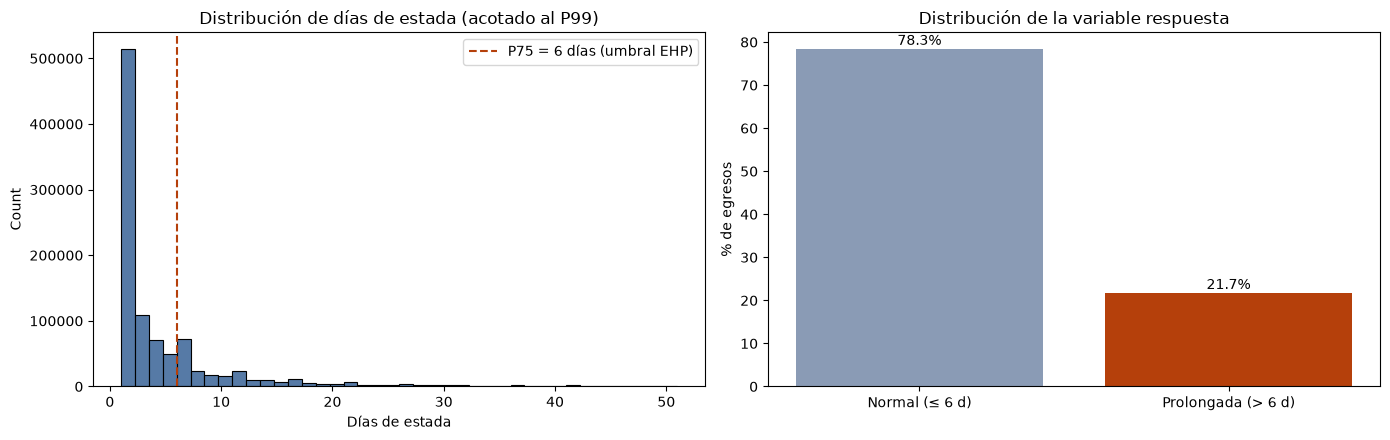

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

p99 = np.percentile(df["DIAS_ESTADA"], 99)
print(df["DIAS_ESTADA"].describe(percentiles=[.5, .75, .95, .99]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df.loc[df["DIAS_ESTADA"] <= p99, "DIAS_ESTADA"], bins=40, ax=ax[0], color="#1D4E89")
ax[0].axvline(p75_estadia, color="#B5400B", ls="--", label=f"P75 = {p75_estadia:.0f} días (umbral EHP)")
ax[0].set_title("Distribución de días de estada (acotado al P99)")
ax[0].set_xlabel("Días de estada"); ax[0].legend()

bal = df["ESTADIA_PROLONGADA_BIN"].value_counts(normalize=True).sort_index() * 100
ax[1].bar(["Normal (≤ 6 d)", "Prolongada (> 6 d)"], bal.values, color=["#8A9BB5", "#B5400B"])
for i, v in enumerate(bal.values): ax[1].text(i, v + 1, f"{v:.1f}%", ha="center")
ax[1].set_title("Distribución de la variable respuesta"); ax[1].set_ylabel("% de egresos")
plt.tight_layout(); plt.show()

**Interpretación del EDA: distribución de la estadía y de la variable respuesta**

- La distribución de `DIAS_ESTADA` es fuertemente asimétrica a la derecha: la mayor parte de los egresos dura entre 1 y 2 días (mediana de 2 días) y existe una cola larga de estadías extensas. Esto confirma lo observado en el Avance 1 (pruebas de normalidad rechazadas) y justifica que el análisis no dependa de la media, sino de umbrales como el percentil 75.

- El umbral de EHP (P75 = 6 días) separa a los egresos en 78,3% de estadías normales y 21,7% de estadías prolongadas. Esta prevalencia no dificulta la estimación por máxima verosimilitud, porque hay cerca de 216.500 eventos. Sí condiciona la clasificación: predecir siempre "normal" daría 78,3% de exactitud sin detectar ninguna EHP. Por eso la exactitud no se usa como medida principal y el punto de corte se elige con el índice de Youden.

- Los valores extremos no se eliminan. Algunos, como el máximo de 17.542 días (unos 48 años), podrían ser estadías excepcionales o errores de registro, y la base no permite distinguirlo. Como la variable respuesta es binaria, su influencia sobre el modelo queda acotada: cuentan igual que cualquier estadía mayor a 6 días.


--- GRUPO_EDAD ---
                 % EHP    size
GRUPO_EDAD                    
80 a 89           38.3   71109
90 y más          38.3   15898
70 a 79           33.1  123670
menor de un año   31.0   24521
60 a 69           28.0  146462
50 a 59           22.9  118518
10 a 19           18.3   62582
40 a 49           15.8  114173
20 a 29           12.2  108966
1 a 9             11.3   58269
30 a 39           11.0  155823

--- GLOSA_PREVISION ---
                 % EHP    size
GLOSA_PREVISION               
CAPREDENA         27.5    7226
FONASA            24.5  795199
DIPRECA           22.1    8597
SISA              21.1    5061
NINGUNA           14.8    8489
ISAPRE             9.1  175419

--- PERTENENCIA_ESTABLECIMIENTO_SALU ---
                                                                   % EHP    size
PERTENENCIA_ESTABLECIMIENTO_SALU                                                
Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS      29.0  615869
No Pertenecientes a

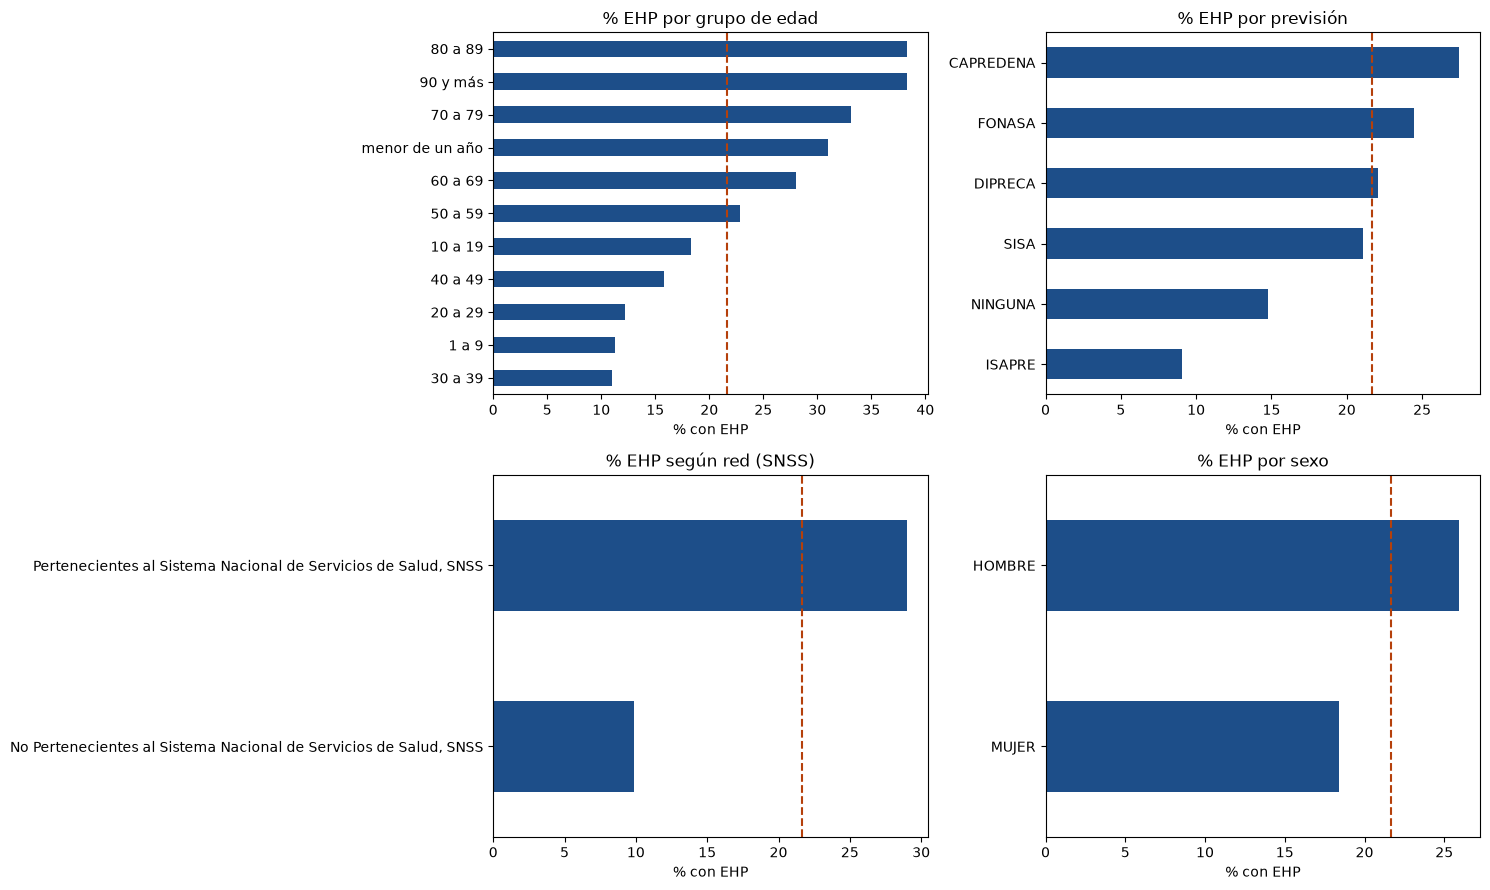

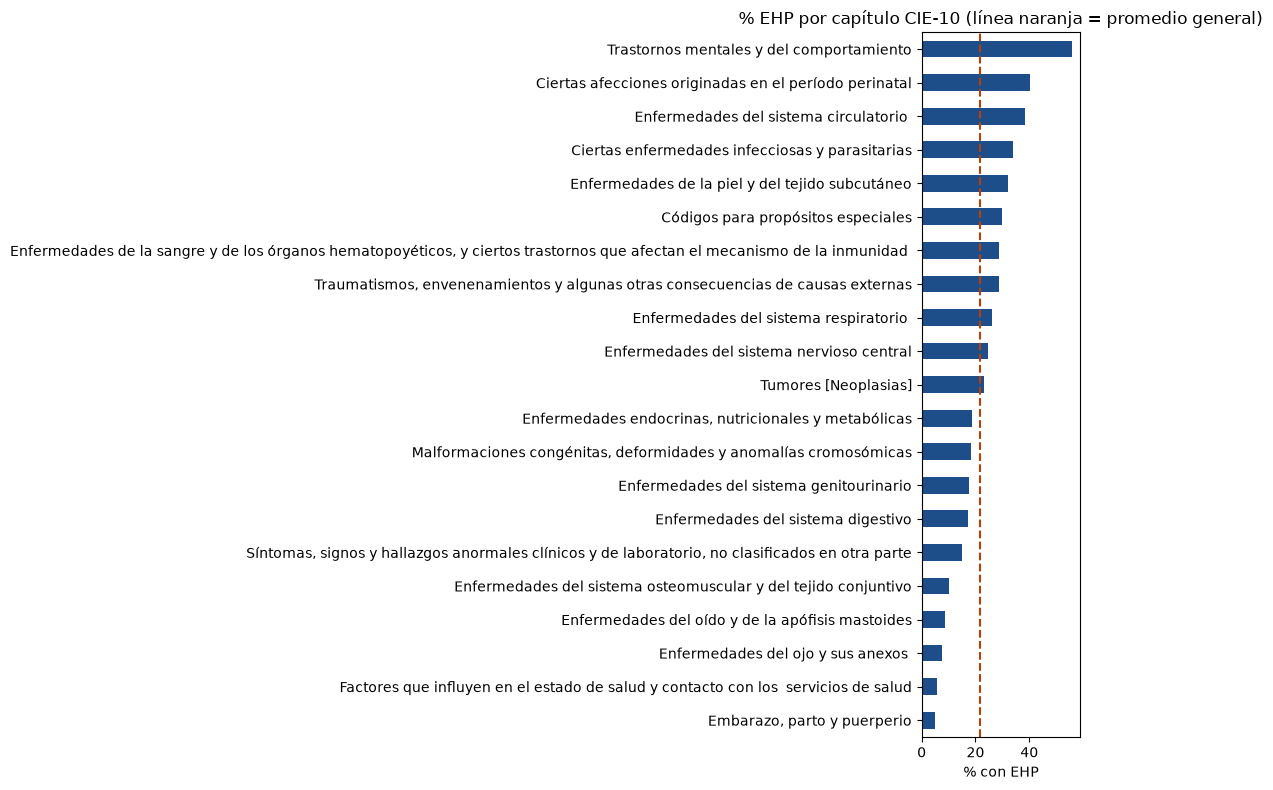

In [7]:

for v in ["GRUPO_EDAD", "GLOSA_PREVISION", "PERTENENCIA_ESTABLECIMIENTO_SALU", "SEXO", "CAPITULO_CIE"]:
    t = df.groupby(v)["ESTADIA_PROLONGADA_BIN"].agg(["mean", "size"])
    t["% EHP"] = (t["mean"] * 100).round(1)
    print(f"\n--- {v} ---")
    print(t[["% EHP", "size"]].sort_values("% EHP", ascending=False).to_string())


def tasa_ehp(var, ax, titulo):
    t = df.groupby(var)["ESTADIA_PROLONGADA_BIN"].mean().mul(100).sort_values()
    t.plot.barh(ax=ax, color="#1D4E89")
    ax.axvline(df["ESTADIA_PROLONGADA_BIN"].mean() * 100, color="#B5400B", ls="--")
    ax.set_title(titulo); ax.set_xlabel("% con EHP"); ax.set_ylabel("")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
tasa_ehp("GRUPO_EDAD", axes[0, 0], "% EHP por grupo de edad")
tasa_ehp("GLOSA_PREVISION", axes[0, 1], "% EHP por previsión")
tasa_ehp("PERTENENCIA_ESTABLECIMIENTO_SALU", axes[1, 0], "% EHP según red (SNSS)")
tasa_ehp("SEXO", axes[1, 1], "% EHP por sexo")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 8))
tasa_ehp("CAPITULO_CIE", ax, "% EHP por capítulo CIE-10 (línea naranja = promedio general)")
plt.tight_layout(); plt.show()

**Interpretación del EDA: tasa de EHP según edad, previsión, red, sexo y diagnóstico**

El promedio general de EHP es 21,7% (línea punteada). Todas las variables muestran diferencias marcadas respecto de ese promedio:

- **Edad:** la tasa de EHP aumenta con la edad a partir de los 50 años: 22,9% entre los 50 y 59, 28,0% entre los 60 y 69, 33,1% entre los 70 y 79, y 38,3% tanto en el grupo de 80 a 89 como en el de 90 años y más. Las tasas más bajas se observan entre los 1 y 9 años (11,3%) y entre los 20 y 39 años (11,0% a 12,2%). La relación no es lineal: los menores de un año tienen una tasa alta (31,0%), lo que ayuda a explicar que la correlación de Spearman del Avance 1 sea pequeña ($\rho = 0{,}191$).

- **Previsión:** ISAPRE presenta la tasa más baja (9,1%, con 175.419 egresos) y FONASA una de las más altas (24,5%, con 795.199 egresos), es decir, 2,7 veces más, consistente con la hipótesis H₁,₂. CAPREDENA aparece primera (27,5%), pero solo tiene 7.226 egresos, por lo que su tasa es menos precisa. NINGUNA (14,8%), SISA (21,1%) y DIPRECA (22,1%) tienen pocos casos.

- **Red hospitalaria:** los establecimientos del SNSS presentan 29,0% de EHP (615.869 egresos), casi el triple que los no pertenecientes al SNSS (9,9%, 384.122 egresos), consistente con la hipótesis H₁,₃.

- **Sexo:** los hombres presentan más EHP (25,9%) que las mujeres (18,4%). Esta variable no estaba entre las hipótesis, y parte de la diferencia se explica por el diagnóstico: el capítulo "Embarazo, parto y puerperio" tiene la tasa más baja de todas (5,0%) y corresponde solo a mujeres.

- **Diagnóstico (capítulo CIE-10):** es la variable con mayor rango de variación. Va desde 5,0% en "Embarazo, parto y puerperio" y 5,8% en "Factores que influyen en el estado de salud" hasta 56,0% en "Trastornos mentales y del comportamiento". Le siguen las afecciones perinatales (40,2%), las enfermedades circulatorias (38,3%) y las infecciosas (34,1%). Los diagnósticos de resolución rápida (ojo 7,5%, oído 8,5%, osteomuscular 10,3%) quedan muy por debajo del promedio.

Estos resultados son bivariados: no controlan el efecto de las demás variables. Por ejemplo, la mayor tasa en el SNSS y en FONASA puede deberse en parte a que atienden más adultos mayores y casos más complejos. Esto justifica el modelamiento multivariado de las secciones siguientes, donde se estima el efecto de cada variable manteniendo constantes las demás.

## 2. Resultados y modelamiento

### 2.1 Codificación de variables
Se construye la matriz de covariables con las 5 variables definidas (`GRUPO_EDAD`, `SEXO`, `GLOSA_PREVISION`, `PERTENENCIA_ESTABLECIMIENTO_SALU` y `CAPITULO_CIE`). Las categóricas se codifican como variables indicadoras, con una categoría de referencia. El modelo se ajusta con todos los egresos de la muestra.

In [8]:
# ==============================================================================
# 2.1 CODIFICACIÓN DE VARIABLES
# ==============================================================================

# Nombres cortos para los 21 capítulos CIE-10 (los originales son muy largos)
nombres_cap = {
    "Enfermedades del sistema digestivo": "Digestivo",
    "Embarazo, parto y puerperio": "Embarazo y parto",
    "Traumatismos, envenenamientos y algunas otras consecuencias de causas externas": "Traumatismos",
    "Enfermedades del sistema respiratorio": "Respiratorio",
    "Enfermedades del sistema circulatorio": "Circulatorio",
    "Enfermedades del sistema genitourinario": "Genitourinario",
    "Tumores [Neoplasias]": "Tumores",
    "Enfermedades del sistema osteomuscular y del tejido conjuntivo": "Osteomuscular",
    "Enfermedades endocrinas, nutricionales y metabólicas": "Endocrino-metabólico",
    "Factores que influyen en el estado de salud y contacto con los servicios de salud": "Factores de salud (Z)",
    "Trastornos mentales y del comportamiento": "Trastornos mentales",
    "Enfermedades del sistema nervioso central": "Sistema nervioso",
    "Ciertas enfermedades infecciosas y parasitarias": "Infecciosas",
    "Enfermedades de la piel y del tejido subcutáneo": "Piel",
    "Síntomas, signos y hallazgos anormales clínicos y de laboratorio, no clasificados en otra parte": "Síntomas mal definidos",
    "Ciertas afecciones originadas en el período perinatal": "Perinatal",
    "Malformaciones congénitas, deformidades y anomalías cromosómicas": "Malformaciones congénitas",
    "Enfermedades de la sangre y de los órganos hematopoyéticos, y ciertos trastornos que afectan el mecanismo de la inmunidad": "Sangre e inmunidad",
    "Enfermedades del ojo y sus anexos": "Ojo",
    "Enfermedades del oído y de la apófisis mastoides": "Oído",
    "Códigos para propósitos especiales": "Códigos especiales (U)",
}
# Se normalizan espacios (algunas glosas del diccionario traen espacios extra)
cap_limpio = df["CAPITULO_CIE"].str.split().str.join(" ")
df["CAPITULO"] = cap_limpio.map(nombres_cap)
assert df["CAPITULO"].notna().all(), "Hay capítulos sin nombre corto"

# Etiquetas para los tramos extremos de edad
df["TRAMO_EDAD"] = df["GRUPO_EDAD"].replace({"menor de un año": "Menor de 1 año"})
orden_edad = df.groupby("TRAMO_EDAD")["EDAD_APROX"].mean().sort_values().index.tolist()
assert len(orden_edad) == 11 and "Menor de 1 año" in orden_edad and "90 y más" in orden_edad

# Categorías de referencia (la primera de cada lista es la que elimina drop_first=True):
#   EDAD = 30 a 39, SEXO = HOMBRE, PREVISION = ISAPRE, RED = No SNSS, CAPITULO = Digestivo
otros_edad = [t for t in orden_edad if t != "30 a 39"]
otros_cap = sorted(c for c in df["CAPITULO"].unique() if c != "Digestivo")
X_base = pd.DataFrame({
    "EDAD": pd.Categorical(df["TRAMO_EDAD"], categories=["30 a 39"] + otros_edad),
    "SEXO": pd.Categorical(df["SEXO"], categories=["HOMBRE", "MUJER"]),
    "PREVISION": pd.Categorical(df["GLOSA_PREVISION"],
                                categories=["ISAPRE", "FONASA", "CAPREDENA", "DIPRECA", "SISA", "NINGUNA"]),
    "RED": pd.Categorical(np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALU"].str.startswith("No"), "No SNSS", "SNSS"),
                          categories=["No SNSS", "SNSS"]),
    "CAPITULO": pd.Categorical(df["CAPITULO"], categories=["Digestivo"] + otros_cap),
}, index=df.index)

# Variables indicadoras con una categoría de referencia
X = pd.get_dummies(X_base, drop_first=True, dtype="int8")
y = df["ESTADIA_PROLONGADA_BIN"].astype(int)

n_parametros = X.shape[1] + 1   # coeficientes más el intercepto
print(f"Matriz de covariables: {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"Eventos (EHP = 1)    : {y.sum():,} ({y.mean()*100:.2f}%)")
print(f"Parámetros del modelo: {n_parametros}")
print(f"Eventos por parámetro: {y.sum() / n_parametros:,.0f}")
print("\nColumnas del modelo:")
print(list(X.columns))

Matriz de covariables: 999,991 filas x 37 columnas
Eventos (EHP = 1)    : 216,544 (21.65%)
Parámetros del modelo: 38
Eventos por parámetro: 5,699

Columnas del modelo:
['EDAD_Menor de 1 año', 'EDAD_1 a 9', 'EDAD_10 a 19', 'EDAD_20 a 29', 'EDAD_40 a 49', 'EDAD_50 a 59', 'EDAD_60 a 69', 'EDAD_70 a 79', 'EDAD_80 a 89', 'EDAD_90 y más', 'SEXO_MUJER', 'PREVISION_FONASA', 'PREVISION_CAPREDENA', 'PREVISION_DIPRECA', 'PREVISION_SISA', 'PREVISION_NINGUNA', 'RED_SNSS', 'CAPITULO_Circulatorio', 'CAPITULO_Códigos especiales (U)', 'CAPITULO_Embarazo y parto', 'CAPITULO_Endocrino-metabólico', 'CAPITULO_Factores de salud (Z)', 'CAPITULO_Genitourinario', 'CAPITULO_Infecciosas', 'CAPITULO_Malformaciones congénitas', 'CAPITULO_Ojo', 'CAPITULO_Osteomuscular', 'CAPITULO_Oído', 'CAPITULO_Perinatal', 'CAPITULO_Piel', 'CAPITULO_Respiratorio', 'CAPITULO_Sangre e inmunidad', 'CAPITULO_Sistema nervioso', 'CAPITULO_Síntomas mal definidos', 'CAPITULO_Trastornos mentales', 'CAPITULO_Traumatismos', 'CAPITULO_Tumore

**Interpretación: codificación**

- **Matriz final:** 999.991 egresos y 37 columnas: edad (10), sexo (1), previsión (5), red SNSS (1) y capítulo CIE-10 (20). Cada variable categórica pierde una columna, su **categoría de referencia**, para evitar colinealidad perfecta. Con el intercepto, el modelo estima 38 parámetros.

- **Edad por tramos:** `GRUPO_EDAD` se incluye como factor porque su relación con la EHP no es lineal en el logit: la tasa es alta en menores de un año, baja en niños y adultos jóvenes, y aumenta desde los 50 años.

- **Categorías de referencia:** se fijaron para que las comparaciones respondan a las hipótesis:
  - **30 a 39 años** para la edad, por ser el tramo más numeroso y con la menor tasa de EHP.
  - **Hombre** para el sexo.
  - **ISAPRE** para la previsión, de modo que el coeficiente de FONASA contrasta directamente lo esperado en H₁,₂ (FONASA > ISAPRE).
  - **No SNSS** para la red, de modo que el coeficiente de SNSS contrasta H₁,₃.
  - **Digestivo** para el capítulo, por ser el más frecuente (143.628 egresos).

- **Tamaño de muestra:** hay cerca de 5.700 eventos por parámetro, muy por encima del mínimo empírico de 10. Por eso el modelo se ajusta con todos los egresos, sin separar una parte de los datos.

- **Nombres cortos:** los capítulos CIE-10 y el tramo de menores de un año se renombraron solo para hacerlos legibles; las categorías son las mismas.

### 2.2 Verificación de multicolinealidad (VIF)
Antes de ajustar el modelo se verifica que las covariables no sean redundantes entre sí. Para cada covariable $j$ se calcula el factor de inflación de la varianza, $VIF_j = 1/(1-R_j^2)$, donde $R_j^2$ es el coeficiente de determinación de $X_j$ regresada sobre las demás covariables. Se usa como referencia habitual que un $VIF > 5$ merece revisión.

In [9]:
# ==============================================================================
# 2.2 FACTOR DE INFLACIÓN DE LA VARIANZA (VIF)
# ==============================================================================
# El VIF de cada covariable es el elemento diagonal de la inversa de la matriz de correlación
corr_X = np.corrcoef(X.to_numpy(dtype="float32"), rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(corr_X)), index=X.columns).sort_values(ascending=False)

print(f"VIF máximo: {vif.max():.2f} | Covariables con VIF > 5: {(vif > 5).sum()} de {len(vif)}")
display(vif.head(10).round(2).to_frame("VIF"))

VIF máximo: 2.27 | Covariables con VIF > 5: 0 de 37


,VIF
EDAD_Menor de 1 año,2.27
CAPITULO_Perinatal,2.11
CAPITULO_Embarazo y parto,2.09
EDAD_60 a 69,1.98
EDAD_70 a 79,1.89
PREVISION_FONASA,1.81
EDAD_50 a 59,1.78
RED_SNSS,1.74
EDAD_40 a 49,1.67
CAPITULO_Respiratorio,1.64


**Interpretación: multicolinealidad**

El VIF máximo es 2,27 (`EDAD_Menor de 1 año`) y ninguna de las 37 covariables supera 5, por lo que no hay evidencia de multicolinealidad severa. FONASA (1,81) y la red SNSS (1,74) tienen valores algo mayores porque la mayoría de los egresos FONASA se atiende en el SNSS, pero esa relación no impide estimar sus efectos por separado.

### 2.3 Modelo de regresión logística
Se implementa el modelo propuesto en el Avance 1. Para cada egreso $i$, $Y_i \sim \text{Bernoulli}(p_i)$ y

$$\ln\frac{p_i}{1-p_i} = \beta_0 + \sum_{k=1}^{10}\beta_k\,\text{Edad}_{ki} + \beta_{11}\,\text{Mujer}_i + \sum_{k=12}^{16}\beta_k\,\text{Previsión}_{ki} + \beta_{17}\,\text{SNSS}_i + \sum_{k=18}^{37}\beta_k\,\text{Capítulo}_{ki}$$

Los parámetros se estiman por máxima verosimilitud, maximizando $\ell(\boldsymbol{\beta}) = \sum_i \left[Y_i\ln p_i + (1-Y_i)\ln(1-p_i)\right]$ con un método iterativo. Los errores estándar se obtienen de la diagonal de $(X^\top W X)^{-1}$, con $W = \text{diag}\{p_i(1-p_i)\}$. Cada coeficiente se contrasta con la prueba de Wald, $z_j = \hat{\beta}_j / SE(\hat{\beta}_j)$, y se interpreta como razón de odds, $OR_j = e^{\hat{\beta}_j}$, con el intervalo de confianza $e^{\hat{\beta}_j \pm 1.96\,SE(\hat{\beta}_j)}$.

In [10]:
# ==============================================================================
# 2.3 ESTIMACIÓN POR MÁXIMA VEROSIMILITUD: COEFICIENTES, WALD, ODDS RATIOS E IC 95%
# ==============================================================================
import statsmodels.api as sm
from scipy import stats

X_sm = sm.add_constant(X.astype("float64"))
modelo = sm.Logit(y, X_sm).fit(disp=0)

print(f"¿Convergió?          : {modelo.mle_retvals['converged']} ({modelo.mle_retvals['iterations']} iteraciones)")
print(f"Egresos (n)          : {int(modelo.nobs):,}")
print(f"Log-verosimilitud    : {modelo.llf:,.2f}")
print(f"Log-veros. modelo nulo: {modelo.llnull:,.2f}")

def formato_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

ic = modelo.conf_int()
tabla_or = pd.DataFrame({
    "β": modelo.params,
    "EE": modelo.bse,
    "z (Wald)": modelo.tvalues,
    "valor_p": modelo.pvalues.map(formato_p),
    "OR": np.exp(modelo.params),
    "IC95_inf": np.exp(ic[0]),
    "IC95_sup": np.exp(ic[1]),
})
pd.set_option("display.max_rows", 60)
display(tabla_or.round(3))
pd.reset_option("display.max_rows")

¿Convergió?          : True (7 iteraciones)
Egresos (n)          : 999,991
Log-verosimilitud    : -444,574.12


Log-veros. modelo nulo: -522,496.69


,β,EE,z (Wald),valor_p,OR,IC95_inf,IC95_sup
const,-2.803,0.014,-200.863,< 0.001,0.061,0.059,0.062
EDAD_Menor de 1 año,-0.030,0.025,-1.217,0.224,0.970,0.924,1.019
EDAD_1 a 9,-0.678,0.017,-40.683,< 0.001,0.507,0.491,0.524
EDAD_10 a 19,-0.238,0.015,-16.223,< 0.001,0.788,0.766,0.811
EDAD_20 a 29,-0.065,0.013,-4.861,< 0.001,0.937,0.913,0.962
EDAD_40 a 49,0.175,0.012,13.992,< 0.001,1.191,1.162,1.221
EDAD_50 a 59,0.491,0.012,41.544,< 0.001,1.634,1.597,1.672
EDAD_60 a 69,0.702,0.011,62.484,< 0.001,2.017,1.973,2.062
EDAD_70 a 79,0.871,0.011,76.396,< 0.001,2.390,2.337,2.444
EDAD_80 a 89,1.014,0.012,81.217,< 0.001,2.757,2.691,2.826


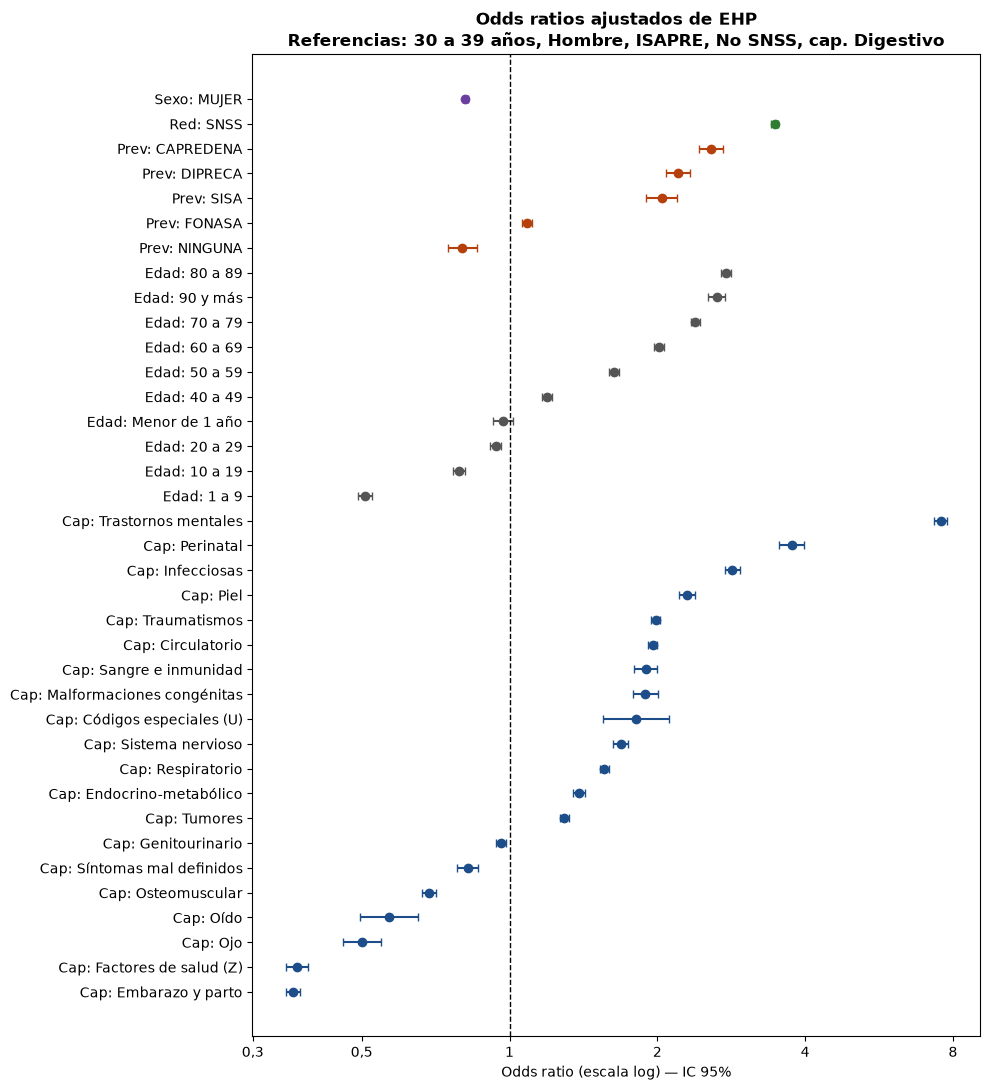

In [11]:
# Gráfico de odds ratios (escala logarítmica) agrupado por variable
import matplotlib.pyplot as plt
grafico = tabla_or.drop("const").copy()
grafico["grupo"] = grafico.index.str.split("_").str[0]
colores = {"CAPITULO": "#1D4E89", "PREVISION": "#B5400B", "RED": "#2E7D32", "SEXO": "#6B3FA0", "EDAD": "#555555"}
orden_grupo = ["CAPITULO", "EDAD", "PREVISION", "RED", "SEXO"]
grafico["orden"] = grafico["grupo"].map({g: i for i, g in enumerate(orden_grupo)})
grafico = grafico.sort_values(["orden", "OR"])

fig, ax = plt.subplots(figsize=(10, 11))
for i, (nombre, fila) in enumerate(grafico.iterrows()):
    c = colores[fila["grupo"]]
    ax.errorbar(fila["OR"], i, xerr=[[fila["OR"] - fila["IC95_inf"]], [fila["IC95_sup"] - fila["OR"]]],
                fmt="o", color=c, ecolor=c, capsize=3)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 2, 4, 8])
ax.set_xticklabels(["0,3", "0,5", "1", "2", "4", "8"])
ax.minorticks_off()
ax.set_yticks(range(len(grafico)))
ax.set_yticklabels([n.replace("CAPITULO_", "Cap: ").replace("PREVISION_", "Prev: ").replace("EDAD_", "Edad: ")
                    .replace("RED_", "Red: ").replace("SEXO_", "Sexo: ") for n in grafico.index])
ax.set_xlabel("Odds ratio (escala log) — IC 95%")
ax.set_title("Odds ratios ajustados de EHP\nReferencias: 30 a 39 años, Hombre, ISAPRE, No SNSS, cap. Digestivo",
             fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación: coeficientes y odds ratios**

Cada OR compara la chance (*odds*) de EHP de una categoría con la de su referencia, **manteniendo constantes las demás variables**. Un OR mayor que 1 indica más chance de EHP y uno menor que 1, menos.

- **Estimación:** el algoritmo convergió en 7 iteraciones, con 38 parámetros y 999.991 egresos.
- **Significancia (Wald):** 36 de los 37 coeficientes tienen $p < 0{,}001$. La excepción es `EDAD_Menor de 1 año` ($p = 0{,}224$). Con este tamaño de muestra casi cualquier diferencia resulta significativa, por lo que la relevancia debe juzgarse por la **magnitud del OR**.
- **Red:** atenderse en el SNSS multiplica la chance de EHP por **3,47** (IC 95%: 3,41–3,53) frente a un establecimiento no perteneciente.
- **Previsión (referencia: ISAPRE):** el efecto de FONASA es pequeño: **OR = 1,09** (IC 95%: 1,06–1,11). CAPREDENA (2,57), DIPRECA (2,21) y SISA (2,04) tienen OR más altos, con intervalos más anchos por ser grupos pequeños. NINGUNA presenta menor chance (0,80).
- **Edad (referencia: 30 a 39 años):** el OR crece desde 0,51 en el tramo de 1 a 9 años hasta 2,76 en el de 80 a 89. En 90 años y más es 2,64, y su intervalo se superpone con el del tramo anterior.
- **Sexo:** las mujeres tienen menor chance que los hombres (**OR = 0,81**; IC 95%: 0,80–0,82), ajustando por el diagnóstico.
- **Diagnóstico (referencia: Digestivo):** es la variable con el mayor rango de OR, desde 0,36 en embarazo y parto hasta 7,55 en trastornos mentales.
- **Del OR a la probabilidad:** el OR no multiplica la probabilidad. El intercepto ($\hat{\beta}_0 = -2{,}803$) da un 5,7% de probabilidad para el perfil de referencia (hombre, 30 a 39 años, ISAPRE, No SNSS, digestivo). El mismo perfil en el SNSS tiene 17,4%: su odds se multiplica por 3,47, pero su probabilidad se multiplica por 3,0.

### 2.4 Contraste de hipótesis y comparación de modelos
La prueba de Wald evalúa cada coeficiente por separado, pero las hipótesis del estudio se refieren a variables completas. Por eso, cada variable se contrasta con la **prueba de razón de verosimilitud**: se ajusta el modelo sin esa variable y se compara con el modelo completo,

$$G = D^2_{\text{reducido}} - D^2_{\text{completo}} \sim \chi^2_q,$$

donde $q$ es el número de coeficientes eliminados y $H_0$ establece que todos ellos valen 0. Se usa $\alpha = 0.05$. Además, se comparan especificaciones del modelo con devianza, AIC, BIC y pseudo $R^2$ de McFadden.

In [12]:
# ==============================================================================
# 2.4.A PRUEBA DE RAZÓN DE VEROSIMILITUD POR VARIABLE
# ==============================================================================
grupos_var = {
    "Edad (GRUPO_EDAD)": [c for c in X.columns if c.startswith("EDAD_")],
    "Sexo": ["SEXO_MUJER"],
    "Previsión": [c for c in X.columns if c.startswith("PREVISION_")],
    "Red (SNSS)": ["RED_SNSS"],
    "Diagnóstico (capítulo CIE-10)": [c for c in X.columns if c.startswith("CAPITULO_")],
}

def ajustar(columnas):
    m = sm.Logit(y, X_sm[columnas]).fit(disp=0)
    assert m.mle_retvals["converged"]
    return m

D_completo = -2 * modelo.llf
D_nula = -2 * modelo.llnull
filas, reducidos = [], {}
for variable, cols in grupos_var.items():
    reducidos[variable] = ajustar([c for c in X_sm.columns if c not in cols])
    D_red = -2 * reducidos[variable].llf
    G = D_red - D_completo
    filas.append({"Variable eliminada": variable, "q": len(cols), "Devianza reducido": D_red, "G": G,
                  "χ² crítico (5%)": stats.chi2.ppf(0.95, len(cols)),
                  "valor_p": formato_p(stats.chi2.sf(G, len(cols))),
                  "G como % de la devianza nula": 100 * G / D_nula})
tabla_lr = pd.DataFrame(filas).set_index("Variable eliminada").sort_values("G", ascending=False)

G_global = D_nula - D_completo
print(f"Devianza nula: {D_nula:,.2f} | Devianza del modelo completo: {D_completo:,.2f}")
print(f"Prueba global: G = {G_global:,.2f}, q = {X.shape[1]}, valor-p {formato_p(stats.chi2.sf(G_global, X.shape[1]))}")
display(tabla_lr.round(2))

Devianza nula: 1,044,993.38 | Devianza del modelo completo: 889,148.24
Prueba global: G = 155,845.14, q = 37, valor-p < 0.001


,q,Devianza reducido,G,χ² crítico (5%),valor_p,G como % de la devianza nula
Variable eliminada,,,,,,
Diagnóstico (capítulo CIE-10),20,937300.01,48151.77,31.41,< 0.001,4.61
Edad (GRUPO_EDAD),10,915959.06,26810.82,18.31,< 0.001,2.57
Red (SNSS),1,914323.93,25175.68,3.84,< 0.001,2.41
Previsión,5,891049.62,1901.38,11.07,< 0.001,0.18
Sexo,1,890602.44,1454.20,3.84,< 0.001,0.14


**Interpretación: prueba de razón de verosimilitud por variable**

- **Prueba global:** se rechaza que todos los coeficientes valgan 0 ($G = 155.845{,}14$; $q = 37$; $p < 0{,}001$).
- **Por variable:** al eliminar cualquiera de las cinco variables, la devianza aumenta de forma significativa ($p < 0{,}001$; todos los $G$ superan ampliamente su valor crítico), por lo que se rechaza $H_0$ para cada una.
- **Magnitud:** el diagnóstico es el que más aporta al ajuste ($G = 48.151{,}77$; $q = 20$), seguido de la edad ($G = 26.810{,}82$; $q = 10$) y la red ($G = 25.175{,}68$; $q = 1$). Previsión ($G = 1.901{,}38$; $q = 5$) y sexo ($G = 1.454{,}20$; $q = 1$) aportan mucho menos. Como se comparan variables con distinto $q$, este orden es descriptivo.

In [13]:
# ==============================================================================
# 2.4.B COMPARACIÓN DE MODELOS: DEVIANZA, AIC, BIC Y PSEUDO R²
# ==============================================================================
# Modelo con la edad como efecto lineal (EDAD_APROX), anidado en el modelo con la edad por tramos
cols_edad = grupos_var["Edad (GRUPO_EDAD)"]
X_lineal = X_sm.drop(columns=cols_edad).copy()
X_lineal["EDAD_APROX"] = df["EDAD_APROX"].astype("float64")
modelo_lineal = sm.Logit(y, X_lineal).fit(disp=0)
assert modelo_lineal.mle_retvals["converged"]

m_sin_diag = reducidos["Diagnóstico (capítulo CIE-10)"]

def resumen(nombre, m):
    return {"Modelo": nombre, "Parámetros": int(m.df_model) + 1, "Devianza": -2 * m.llf,
            "AIC": m.aic, "BIC": m.bic, "R² McFadden": m.prsquared}

comparacion_modelos = pd.DataFrame([
    {"Modelo": "M0: nulo (solo intercepto)", "Parámetros": 1, "Devianza": D_nula,
     "AIC": D_nula + 2, "BIC": D_nula + np.log(modelo.nobs), "R² McFadden": 0.0},
    resumen("M1: edad por tramos, sexo, previsión y red (sin diagnóstico)", m_sin_diag),
    resumen("M2: completo con edad lineal", modelo_lineal),
    resumen("M3: completo con edad por tramos", modelo),
]).set_index("Modelo")
display(comparacion_modelos.round(4))

G_edad = 2 * (modelo.llf - modelo_lineal.llf)
q_edad = int(modelo.df_model - modelo_lineal.df_model)
print(f"M2 vs. M3 (edad lineal vs. por tramos): G = {G_edad:,.2f}, q = {q_edad}, "
      f"valor-p {formato_p(stats.chi2.sf(G_edad, q_edad))}")

,Parámetros,Devianza,AIC,BIC,R² McFadden
Modelo,,,,,
M0: nulo (solo intercepto),1,1.044993e+06,1.044995e+06,1.045007e+06,0.0000
"M1: edad por tramos, sexo, previsión y red (sin diagnóstico)",18,9.373000e+05,9.373360e+05,9.375487e+05,0.1031
M2: completo con edad lineal,29,8.904922e+05,8.905502e+05,8.908929e+05,0.1478
M3: completo con edad por tramos,38,8.891482e+05,8.892242e+05,8.896732e+05,0.1491


M2 vs. M3 (edad lineal vs. por tramos): G = 1,343.99, q = 9, valor-p < 0.001


**Interpretación: comparación de modelos**

- **Modelo elegido:** M3 (completo, con la edad por tramos) tiene la menor devianza, el menor AIC (889.224) y el menor BIC (889.673).
- **Aporte del diagnóstico:** al pasar de M1 a M3, el pseudo $R^2$ de McFadden sube de 0,103 a 0,149 y el AIC baja de 937.336 a 889.224.
- **Edad por tramos o lineal:** como M2 está anidado en M3, se comparan con razón de verosimilitud: $G = 1.343{,}99$, $q = 9$, $p < 0{,}001$. Los tramos mejoran el ajuste a pesar de sus 9 parámetros adicionales, aunque la ganancia en el pseudo $R^2$ es pequeña (de 0,148 a 0,149).
- **Precaución:** con cerca de un millón de egresos, AIC y BIC tienden a favorecer los modelos más grandes. En este caso, la elección también se apoya en el gráfico de linealidad siguiente y en la pregunta de investigación, que usa `GRUPO_EDAD`.

,edad,tasa,n,logit_empirico
TRAMO_EDAD,,,,
Menor de 1 año,0.5,0.310,24521,-0.799
1 a 9,5.0,0.113,58269,-2.059
10 a 19,14.5,0.183,62582,-1.494
20 a 29,24.5,0.122,108966,-1.974
30 a 39,34.5,0.110,155823,-2.090
40 a 49,44.5,0.158,114173,-1.675
50 a 59,54.5,0.229,118518,-1.215
60 a 69,64.5,0.280,146462,-0.943
70 a 79,74.5,0.331,123670,-0.704


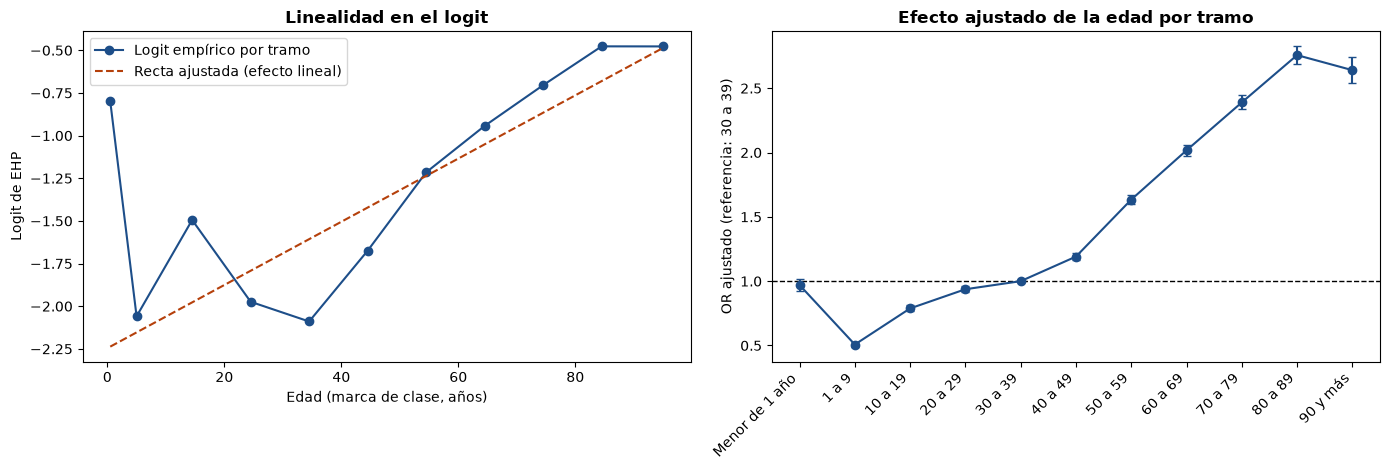

In [14]:
# Linealidad en el logit: logit empírico por tramo y OR ajustados de la edad
resumen_edad = df.groupby("TRAMO_EDAD").agg(edad=("EDAD_APROX", "mean"), tasa=("ESTADIA_PROLONGADA_BIN", "mean"),
                                            n=("ESTADIA_PROLONGADA_BIN", "size")).sort_values("edad")
resumen_edad["logit_empirico"] = np.log(resumen_edad["tasa"] / (1 - resumen_edad["tasa"]))
display(resumen_edad.round(3))

recta = np.polyval(np.polyfit(resumen_edad["edad"], resumen_edad["logit_empirico"], 1,
                              w=np.sqrt(resumen_edad["n"])), resumen_edad["edad"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.plot(resumen_edad["edad"], resumen_edad["logit_empirico"], marker="o", color="#1D4E89", label="Logit empírico por tramo")
ax1.plot(resumen_edad["edad"], recta, ls="--", color="#B5400B", label="Recta ajustada (efecto lineal)")
ax1.set_xlabel("Edad (marca de clase, años)"); ax1.set_ylabel("Logit de EHP")
ax1.set_title("Linealidad en el logit", fontweight="bold"); ax1.legend()

etiquetas = [t for t in resumen_edad.index]
or_edad, inf_edad, sup_edad = [], [], []
for t in etiquetas:
    if t == "30 a 39":
        or_edad.append(1.0); inf_edad.append(1.0); sup_edad.append(1.0)
    else:
        fila = tabla_or.loc[f"EDAD_{t}"]
        or_edad.append(fila["OR"]); inf_edad.append(fila["IC95_inf"]); sup_edad.append(fila["IC95_sup"])
or_edad, inf_edad, sup_edad = map(np.array, (or_edad, inf_edad, sup_edad))
ax2.errorbar(range(len(etiquetas)), or_edad, yerr=[or_edad - inf_edad, sup_edad - or_edad], fmt="o-", color="#1D4E89", capsize=3)
ax2.axhline(1, color="black", lw=1, ls="--")
ax2.set_xticks(range(len(etiquetas))); ax2.set_xticklabels(etiquetas, rotation=45, ha="right")
ax2.set_ylabel("OR ajustado (referencia: 30 a 39)")
ax2.set_title("Efecto ajustado de la edad por tramo", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación: linealidad en el logit y efecto de la edad**

- **Gráfico izquierdo:** el logit empírico no sigue una recta: es alto en menores de un año ($-0{,}80$), cae en el tramo de 1 a 9 años ($-2{,}06$), sube en el de 10 a 19 ($-1{,}49$), baja hasta el mínimo en el de 30 a 39 ($-2{,}09$) y crece desde entonces hasta $-0{,}48$. Esto no cumple la linealidad en el logit y respalda incluir la edad por tramos.
- **Gráfico derecho:** al ajustar por las demás variables, la forma cambia. El OR de los menores de un año baja de 3,63 (crudo) a 0,97 (IC 95%: 0,92–1,02), de modo que no se distinguen del tramo de 30 a 39 años. Su tasa alta se asocia en gran parte con las demás variables del modelo, como el diagnóstico perinatal. Desde el tramo de 1 a 9 años, el OR crece de forma sostenida hasta los 80 a 89.

In [15]:
# ==============================================================================
# 2.4.C OR CRUDO VS. AJUSTADO Y COHERENCIA CON LOS TESTS DEL AVANCE 1
# ==============================================================================
def or_con_ic(m, var, cuantos=None):
    i = m.conf_int().loc[var]
    return f"{np.exp(m.params[var]):.2f} ({np.exp(i[0]):.2f}–{np.exp(i[1]):.2f})"

m_crudo_prev = ajustar(["const"] + grupos_var["Previsión"])
m_crudo_red = ajustar(["const", "RED_SNSS"])
m_crudo_edad = ajustar(["const"] + cols_edad)
m_prev_red = ajustar(["const"] + grupos_var["Previsión"] + ["RED_SNSS"])

filas = []
for t in ["60 a 69", "70 a 79", "80 a 89", "90 y más", "Menor de 1 año"]:
    v = f"EDAD_{t}"
    filas.append({"Comparación": f"Edad {t} vs. 30 a 39", "OR crudo (IC 95%)": or_con_ic(m_crudo_edad, v),
                  "OR ajustado solo por previsión y red (IC 95%)": "–", "OR modelo completo (IC 95%)": or_con_ic(modelo, v)})
for v, m_c, etiqueta in [("PREVISION_FONASA", m_crudo_prev, "FONASA vs. ISAPRE"),
                         ("RED_SNSS", m_crudo_red, "SNSS vs. No SNSS")]:
    filas.append({"Comparación": etiqueta, "OR crudo (IC 95%)": or_con_ic(m_c, v),
                  "OR ajustado solo por previsión y red (IC 95%)": or_con_ic(m_prev_red, v),
                  "OR modelo completo (IC 95%)": or_con_ic(modelo, v)})
display(pd.DataFrame(filas).set_index("Comparación"))

# ¿Dónde se atienden los afiliados de cada previsión?
pct_snss = (X["RED_SNSS"].groupby(df["GLOSA_PREVISION"]).mean() * 100).round(1).sort_values(ascending=False)
print("% de egresos atendidos en establecimientos del SNSS, por previsión:")
print(pct_snss.to_string())

# Tests bivariados del Avance 1 (χ² y V de Cramér) frente a la prueba multivariada
v_cramer = {"Edad (GRUPO_EDAD)": 0.226, "Previsión": 0.143, "Red (SNSS)": 0.226, "Diagnóstico (capítulo CIE-10)": 0.283}
coherencia = pd.DataFrame({
    "V de Cramér (Avance 1)": pd.Series(v_cramer),
    "G (modelo completo)": tabla_lr["G"].round(1),
    "q": tabla_lr["q"],
    "valor_p": tabla_lr["valor_p"],
}).loc[list(v_cramer)]
display(coherencia)

,OR crudo (IC 95%),OR ajustado solo por previsión y red (IC 95%),OR modelo completo (IC 95%)
Comparación,,,
Edad 60 a 69 vs. 30 a 39,3.15 (3.09–3.21),–,2.02 (1.97–2.06)
Edad 70 a 79 vs. 30 a 39,4.00 (3.92–4.08),–,2.39 (2.34–2.44)
Edad 80 a 89 vs. 30 a 39,5.02 (4.91–5.13),–,2.76 (2.69–2.83)
Edad 90 y más vs. 30 a 39,5.02 (4.84–5.20),–,2.64 (2.54–2.74)
Edad Menor de 1 año vs. 30 a 39,3.63 (3.52–3.75),–,0.97 (0.92–1.02)
FONASA vs. ISAPRE,3.25 (3.19–3.31),1.09 (1.06–1.11),1.09 (1.06–1.11)
SNSS vs. No SNSS,3.73 (3.69–3.78),3.88 (3.82–3.94),3.47 (3.41–3.53)


% de egresos atendidos en establecimientos del SNSS, por previsión:
GLOSA_PREVISION
FONASA       76.6
NINGUNA      41.3
DIPRECA       4.9
CAPREDENA     3.2
SISA          1.9
ISAPRE        1.3


,V de Cramér (Avance 1),G (modelo completo),q,valor_p
Edad (GRUPO_EDAD),0.226,26810.8,10,< 0.001
Previsión,0.143,1901.4,5,< 0.001
Red (SNSS),0.226,25175.7,1,< 0.001
Diagnóstico (capítulo CIE-10),0.283,48151.8,20,< 0.001


**Interpretación: OR crudos y ajustados, y coherencia con el Avance 1**

**Contraste de las hipótesis sobre la EHP**

| Hipótesis | Prueba de razón de verosimilitud | Efecto ajustado (IC 95%) | Decisión |
| :--- | :--- | :--- | :--- |
| $H_{0,1}$ (edad) | $G = 26.810{,}82$; $q = 10$; $p < 0{,}001$ | 60 a 69: 2,02 (1,97–2,06); 70 a 79: 2,39 (2,34–2,44); 80 a 89: 2,76 (2,69–2,83); 90 y más: 2,64 (2,54–2,74) | Se rechaza $H_0$ |
| $H_{0,2}$ (previsión) | $G = 1.901{,}38$; $q = 5$; $p < 0{,}001$ | FONASA vs. ISAPRE: 1,09 (1,06–1,11) | Se rechaza $H_0$, con un efecto pequeño de FONASA |
| $H_{0,3}$ (red) | $G = 25.175{,}68$; $q = 1$; $p < 0{,}001$ | SNSS vs. No SNSS: 3,47 (3,41–3,53) | Se rechaza $H_0$ |

**Coherencia con los tests del Avance 1**

- **Mismas decisiones:** los tests $\chi^2$ del Avance 1 rechazaron la independencia entre la EHP y la edad ($V = 0{,}226$), la previsión ($V = 0{,}143$), la red ($V = 0{,}226$) y el diagnóstico ($V = 0{,}283$, con la primera letra del código CIE-10). El modelo mantiene esas decisiones y ahora las ajusta por las demás variables.
- **Red:** su efecto casi no cambia al ajustar, de 3,73 (crudo) a 3,47.
- **Edad:** el efecto se reduce, pero se mantiene (de 5,02 a 2,76 en el tramo de 80 a 89 años). La relación no monótona con la EHP es coherente con la correlación de Spearman pequeña del Avance 1 ($\rho = 0{,}191$), aunque esa prueba usó los días de estada.
- **Previsión:** es el cambio más marcado. El OR de FONASA frente a ISAPRE baja de 3,25 a 1,09 con solo ajustar por la red, porque el 76,6% de los egresos FONASA se atiende en el SNSS, frente al 1,3% de los de ISAPRE. La asociación bivariada del Avance 1 se debe en gran parte a dónde se atiende cada grupo.

**Precauciones:** son asociaciones, no efectos causales. Además, el OR no es colapsable: puede cambiar al agregar covariables aunque estas no sean factores de confusión. Por eso, la comparación entre OR crudos y ajustados es orientativa.

### 2.5 Bondad de ajuste y diagnóstico
Se evalúa si el modelo representa bien los datos con el pseudo $R^2$ de McFadden, la prueba de Hosmer–Lemeshow,

$$\hat{C} = \sum_{k=1}^{g}\frac{(O_k - E_k)^2}{E_k(1 - E_k/n_k)} \sim \chi^2_{g-2},$$

y el análisis de residuos e influencia. Como todas las covariables son categóricas, muchos egresos comparten el mismo perfil, por lo que el diagnóstico de influencia se hace por **patrón de covariables** (datos agrupados: $Y_k \sim \text{Bin}(n_k, p_k)$).

R² de McFadden: 0.1491
Probabilidad media estimada: 0.2165 | Proporción observada: 0.2165
Hosmer–Lemeshow: C = 3,403.74, gl = 8, χ² crítico (5%) = 15.51, valor-p < 0.001
Diferencia absoluta media por grupo (estimada vs. observada): 0.0183


,n,Observados,Esperados,p_media,Prop. observada,Aporte a C
decil,,,,,,
0,100137,2486,3187.581,0.032,0.025,159.494
1,118669,6204,7058.855,0.059,0.052,110.074
2,81371,3353,5968.612,0.073,0.041,1236.966
3,102370,10825,10761.354,0.105,0.106,0.421
4,98090,16389,14540.960,0.148,0.167,275.748
5,99592,21061,19865.548,0.199,0.211,89.864
6,99903,29266,26470.629,0.265,0.293,401.611
7,102476,37544,34596.968,0.338,0.366,378.982
8,101138,42501,42961.440,0.425,0.420,8.579


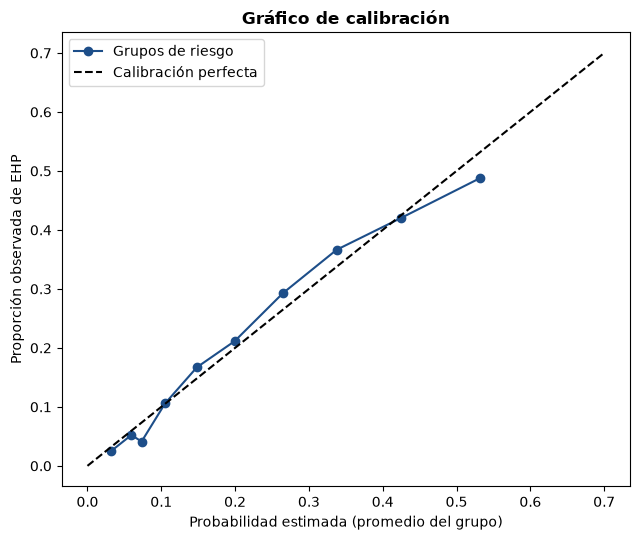

In [16]:
# ==============================================================================
# 2.5.A PSEUDO R² Y PRUEBA DE HOSMER–LEMESHOW
# ==============================================================================
p_hat = modelo.predict(X_sm).to_numpy()
y_np = y.to_numpy()

deciles = pd.qcut(p_hat, 10, labels=False, duplicates="drop")
tabla_hl = pd.DataFrame({"decil": deciles, "y": y_np, "p": p_hat}).groupby("decil").agg(
    n=("y", "size"), Observados=("y", "sum"), Esperados=("p", "sum"), p_media=("p", "mean"))
tabla_hl["Prop. observada"] = tabla_hl["Observados"] / tabla_hl["n"]
tabla_hl["Aporte a C"] = (tabla_hl["Observados"] - tabla_hl["Esperados"])**2 / (
    tabla_hl["Esperados"] * (1 - tabla_hl["Esperados"] / tabla_hl["n"]))
C_hl = tabla_hl["Aporte a C"].sum()
g = len(tabla_hl)

print(f"R² de McFadden: {modelo.prsquared:.4f}")
print(f"Probabilidad media estimada: {p_hat.mean():.4f} | Proporción observada: {y_np.mean():.4f}")
print(f"Hosmer–Lemeshow: C = {C_hl:,.2f}, gl = {g - 2}, χ² crítico (5%) = {stats.chi2.ppf(0.95, g - 2):.2f}, "
      f"valor-p {formato_p(stats.chi2.sf(C_hl, g - 2))}")
print(f"Diferencia absoluta media por grupo (estimada vs. observada): "
      f"{(tabla_hl['p_media'] - tabla_hl['Prop. observada']).abs().mean():.4f}")
display(tabla_hl.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(tabla_hl["p_media"], tabla_hl["Prop. observada"], marker="o", color="#1D4E89", label="Grupos de riesgo")
ax.plot([0, 0.7], [0, 0.7], "k--", label="Calibración perfecta")
ax.set_xlabel("Probabilidad estimada (promedio del grupo)"); ax.set_ylabel("Proporción observada de EHP")
ax.set_title("Gráfico de calibración", fontweight="bold"); ax.legend()
plt.tight_layout(); plt.show()

Egresos con |residuo de Pearson| > 2 : 4.94%
Egresos con |residuo de devianza| > 2: 2.59%



Patrones de covariables: 3,387 | Suma del apalancamiento: 38.00 (debe ser 38)
X² de Pearson agrupado: 31,138.4 | Devianza agrupada: 30,308.3 | gl = 3,349
X²/gl = 9.30 | Patrones con n_k >= 5 esperados en ambas clases: 38.2%
Patrones con |residuo estandarizado| > 2: 27.7% (concentran 74.7% de los egresos)
Distancia de Cook máxima: 3.840 | Patrones con Cook > 1: 7



Patrones más influyentes (mayor distancia de Cook):


,EDAD,SEXO,PREVISION,RED,CAPITULO,n,Observados,Esperados,r_std,H,Cook
39,Menor de 1 año,HOMBRE,FONASA,SNSS,Perinatal,6046,2444,2744.6,-11.3,0.531,3.840
15,20 a 29,MUJER,FONASA,SNSS,Embarazo y parto,38869,2017,2306.0,-8.8,0.508,2.123
8,30 a 39,MUJER,FONASA,SNSS,Embarazo y parto,36930,2602,2328.3,8.2,0.487,1.670
159,Menor de 1 año,HOMBRE,FONASA,SNSS,Respiratorio,2647,440,679.3,-12.5,0.278,1.588
137,30 a 39,MUJER,FONASA,No SNSS,Endocrino-metabólico,5687,16,392.1,-20.8,0.101,1.274
53,80 a 89,HOMBRE,FONASA,SNSS,Circulatorio,5292,2367,2920.5,-16.5,0.145,1.221
36,1 a 9,HOMBRE,FONASA,SNSS,Infecciosas,1695,126,419.9,-17.7,0.123,1.148
503,Menor de 1 año,MUJER,FONASA,SNSS,Malformaciones congénitas,587,308,149.0,16.1,0.122,0.951


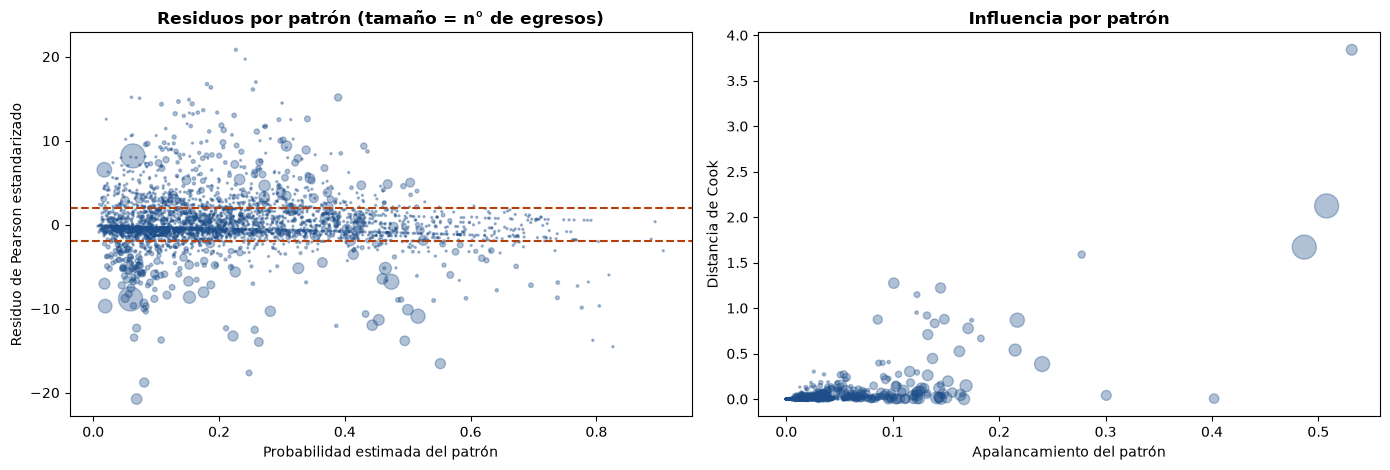

In [17]:
# ==============================================================================
# 2.5.B RESIDUOS E INFLUENCIA POR PATRÓN DE COVARIABLES
# ==============================================================================
from scipy.special import xlogy

# Residuos individuales de Pearson y de devianza
r_ind = (y_np - p_hat) / np.sqrt(p_hat * (1 - p_hat))
d_ind = np.sign(y_np - p_hat) * np.sqrt(-2 * (xlogy(y_np, p_hat) + xlogy(1 - y_np, 1 - p_hat)))
print(f"Egresos con |residuo de Pearson| > 2 : {(np.abs(r_ind) > 2).mean() * 100:.2f}%")
print(f"Egresos con |residuo de devianza| > 2: {(np.abs(d_ind) > 2).mean() * 100:.2f}%")

# Agrupación por patrón de covariables: Y_k ~ Bin(n_k, p_k)
id_patron = X_base.groupby(list(X_base.columns), observed=True, sort=False).ngroup().to_numpy()
K = id_patron.max() + 1
n_k = np.bincount(id_patron, minlength=K).astype(float)
O_k = np.bincount(id_patron, weights=y_np, minlength=K)
primera = pd.Series(np.arange(len(id_patron))).groupby(id_patron).first().to_numpy()
X_k = X_sm.to_numpy()[primera]
p_k = p_hat[primera]
w_k = p_k * (1 - p_k)

inv_info = np.linalg.inv((X_k * (n_k * w_k)[:, None]).T @ X_k)
H_k = n_k * w_k * np.einsum("ij,jk,ik->i", X_k, inv_info, X_k)   # apalancamiento del patrón
r_k = (O_k - n_k * p_k) / np.sqrt(n_k * w_k)                     # residuo de Pearson del patrón
r_std = r_k / np.sqrt(np.clip(1 - H_k, 1e-10, None))             # residuo estandarizado
cook = r_std**2 * H_k / ((1 - H_k + 1e-10) * X_k.shape[1])       # distancia de Cook

X2 = (r_k**2).sum()
D_g = 2 * (xlogy(O_k, O_k / (n_k * p_k)) + xlogy(n_k - O_k, (n_k - O_k) / (n_k * (1 - p_k)))).sum()
gl_g = K - X_k.shape[1]
print(f"\nPatrones de covariables: {K:,} | Suma del apalancamiento: {H_k.sum():.2f} (debe ser {X_k.shape[1]})")
print(f"X² de Pearson agrupado: {X2:,.1f} | Devianza agrupada: {D_g:,.1f} | gl = {gl_g:,}")
print(f"X²/gl = {X2 / gl_g:.2f} | Patrones con n_k >= 5 esperados en ambas clases: "
      f"{((n_k * p_k >= 5) & (n_k * (1 - p_k) >= 5)).mean() * 100:.1f}%")
print(f"Patrones con |residuo estandarizado| > 2: {(np.abs(r_std) > 2).mean() * 100:.1f}% "
      f"(concentran {n_k[np.abs(r_std) > 2].sum() / n_k.sum() * 100:.1f}% de los egresos)")
print(f"Distancia de Cook máxima: {cook.max():.3f} | Patrones con Cook > 1: {(cook > 1).sum()}")

filas_base = X_base.iloc[primera].reset_index(drop=True)
diag = filas_base.assign(n=n_k.astype(int), Observados=O_k.astype(int), Esperados=(n_k * p_k).round(1),
                         r_std=r_std.round(1), H=H_k.round(3), Cook=cook.round(3))
print("\nPatrones más influyentes (mayor distancia de Cook):")
display(diag.sort_values("Cook", ascending=False).head(8))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.scatter(p_k, r_std, s=np.clip(n_k / 100, 2, 300), alpha=0.35, color="#1D4E89")
ax1.axhline(2, color="#B5400B", ls="--"); ax1.axhline(-2, color="#B5400B", ls="--")
ax1.set_xlabel("Probabilidad estimada del patrón"); ax1.set_ylabel("Residuo de Pearson estandarizado")
ax1.set_title("Residuos por patrón (tamaño = n° de egresos)", fontweight="bold")
ax2.scatter(H_k, cook, s=np.clip(n_k / 100, 2, 300), alpha=0.35, color="#1D4E89")
ax2.set_xlabel("Apalancamiento del patrón"); ax2.set_ylabel("Distancia de Cook")
ax2.set_title("Influencia por patrón", fontweight="bold")
plt.tight_layout(); plt.show()

In [18]:
# ==============================================================================
# 2.5.C ANÁLISIS DE SENSIBILIDAD: SOBREDISPERSIÓN Y PATRONES INFLUYENTES
# ==============================================================================
# a) Errores estándar escalados por la sobredispersión estimada (φ = X²/gl)
phi = X2 / gl_g
ee_esc = modelo.bse * np.sqrt(phi)

# b) Modelo reajustado sin los patrones con distancia de Cook > 1
excluir = np.where(cook > 1)[0]
conservar = ~np.isin(id_patron, excluir)
m_sin_influyentes = sm.Logit(y[conservar], X_sm[conservar]).fit(disp=0)
assert m_sin_influyentes.mle_retvals["converged"]
print(f"φ = {phi:.2f} | Patrones excluidos: {len(excluir)} ({(~conservar).sum():,} egresos, {(~conservar).mean() * 100:.1f}%)")

sensibilidad = pd.DataFrame({
    "OR": np.exp(modelo.params),
    "IC inf (original)": np.exp(modelo.params - 1.96 * modelo.bse),
    "IC sup (original)": np.exp(modelo.params + 1.96 * modelo.bse),
    "IC inf (escalado)": np.exp(modelo.params - 1.96 * ee_esc),
    "IC sup (escalado)": np.exp(modelo.params + 1.96 * ee_esc),
    "OR sin influyentes": np.exp(m_sin_influyentes.params),
}).drop("const")
principales = ["EDAD_Menor de 1 año", "EDAD_60 a 69", "EDAD_70 a 79", "EDAD_80 a 89", "EDAD_90 y más", "SEXO_MUJER",
               "PREVISION_FONASA", "PREVISION_CAPREDENA", "PREVISION_DIPRECA", "PREVISION_SISA", "PREVISION_NINGUNA",
               "RED_SNSS", "CAPITULO_Trastornos mentales", "CAPITULO_Perinatal", "CAPITULO_Embarazo y parto"]
display(sensibilidad.loc[principales].round(3))

cruzan_uno = sensibilidad[(sensibilidad["IC inf (escalado)"] <= 1) & (sensibilidad["IC sup (escalado)"] >= 1)].index.tolist()
print("Coeficientes cuyo IC escalado incluye el 1:", cruzan_uno)
print(f"Mayor cambio relativo del OR sin influyentes: "
      f"{((sensibilidad['OR sin influyentes'] / sensibilidad['OR'] - 1).abs() * 100).sort_values(ascending=False).head(5).round(1).to_dict()}")

# Prueba de razón de verosimilitud por variable, escalada por φ
lr_escalada = tabla_lr[["q", "G"]].copy()
lr_escalada["G/φ"] = lr_escalada["G"] / phi
lr_escalada["χ² crítico (5%)"] = stats.chi2.ppf(0.95, lr_escalada["q"])
lr_escalada["Se rechaza H0"] = lr_escalada["G/φ"] > lr_escalada["χ² crítico (5%)"]
display(lr_escalada.round(2))

φ = 9.30 | Patrones excluidos: 7 (97,166 egresos, 9.7%)


,OR,IC inf (original),IC sup (original),IC inf (escalado),IC sup (escalado),OR sin influyentes
EDAD_Menor de 1 año,0.970,0.924,1.019,0.836,1.126,1.128
EDAD_60 a 69,2.017,1.973,2.062,1.886,2.157,1.982
EDAD_70 a 79,2.390,2.337,2.444,2.232,2.558,2.349
EDAD_80 a 89,2.757,2.691,2.826,2.559,2.971,2.833
EDAD_90 y más,2.640,2.541,2.744,2.349,2.968,2.609
SEXO_MUJER,0.813,0.804,0.821,0.787,0.839,0.797
PREVISION_FONASA,1.086,1.062,1.111,1.013,1.164,1.115
PREVISION_CAPREDENA,2.571,2.430,2.720,2.164,3.054,2.578
PREVISION_DIPRECA,2.208,2.087,2.335,1.860,2.620,2.212
PREVISION_SISA,2.044,1.901,2.197,1.639,2.549,2.047


Coeficientes cuyo IC escalado incluye el 1: ['EDAD_Menor de 1 año', 'EDAD_20 a 29', 'CAPITULO_Genitourinario']
Mayor cambio relativo del OR sin influyentes: {'EDAD_Menor de 1 año': 16.3, 'CAPITULO_Perinatal': 7.1, 'CAPITULO_Endocrino-metabólico': 6.6, 'CAPITULO_Infecciosas': 6.3, 'CAPITULO_Malformaciones congénitas': 4.9}


,q,G,G/φ,χ² crítico (5%),Se rechaza H0
Variable eliminada,,,,,
Diagnóstico (capítulo CIE-10),20,48151.77,5178.82,31.41,True
Edad (GRUPO_EDAD),10,26810.82,2883.56,18.31,True
Red (SNSS),1,25175.68,2707.70,3.84,True
Previsión,5,1901.38,204.50,11.07,True
Sexo,1,1454.20,156.40,3.84,True


**Interpretación: bondad de ajuste, residuos e influencia**

- **Ajuste global:** el pseudo $R^2$ de McFadden es 0,149, bajo el rango de 0,2 a 0,4 que suele considerarse bueno. Las cinco variables explican solo parte de la variación de la EHP.
- **Hosmer–Lemeshow:** se rechaza el buen ajuste ($\hat{C} = 3.403{,}74$; $gl = 8$; $p < 0{,}001$). Con esta muestra, la prueba detecta diferencias pequeñas, por lo que debe leerse junto con el gráfico de calibración. La probabilidad media estimada coincide con la observada (0,2165) y la diferencia media por grupo es de 1,83 puntos porcentuales. Las mayores desviaciones están en el tercer grupo (0,073 estimado frente a 0,041 observado) y en el de mayor riesgo (0,531 frente a 0,487). Los grupos no son exactamente iguales porque muchos egresos comparten la misma probabilidad.
- **Residuos:** el 4,94% de los egresos tiene un residuo de Pearson mayor que 2 en valor absoluto, y el 2,59% un residuo de devianza mayor que 2. Por patrón de covariables hay más desajuste: el 27,7% de los 3.387 patrones supera $|2|$, y estos concentran el 74,7% de los egresos.
- **Sobredispersión:** $X^2/gl = 9{,}30$, cuando un modelo bien especificado daría un valor cercano a 1. Es una medida orientativa, porque solo el 38,2% de los patrones tiene al menos 5 casos esperados en ambas categorías. Indica que el modelo aditivo, sin interacciones ni variables de gravedad, no recoge toda la variación entre perfiles, y que los errores estándar podrían ser demasiado pequeños.
- **Influencia:** 7 patrones tienen una distancia de Cook mayor que 1; el máximo es 3,84 (menores de un año, hombres, FONASA, SNSS, perinatal). Son patrones con muchos egresos y no errores evidentes, por lo que se conservan en el modelo.

**Análisis de sensibilidad**

- **Errores estándar escalados** por $\sqrt{\hat{\phi}}$, con $\hat{\phi} = 9{,}30$: los intervalos se ensanchan cerca de 3 veces. Solo tres coeficientes pasan a incluir el 1: menores de un año, 20 a 29 años y genitourinario. FONASA sigue por encima de 1, aunque con poco margen (IC: 1,01–1,16), y SNSS se mantiene en 3,29–3,65. Las cinco variables siguen siendo significativas con $G/\hat{\phi}$; la previsión, por ejemplo, obtiene 204,50 frente a un valor crítico de 11,07.
- **Modelo sin los 7 patrones influyentes** (97.166 egresos, 9,7%): los principales OR cambian poco (SNSS de 3,47 a 3,42; FONASA de 1,09 a 1,12; 80 a 89 años de 2,76 a 2,83). El mayor cambio es el de los menores de un año (de 0,97 a 1,13).

**Conclusión:** la dirección y el orden de los efectos principales son estables, pero los intervalos nominales de la sección 2.3 probablemente son demasiado estrechos. El efecto ajustado de los menores de un año no es estable, por lo que no debe interpretarse como un resultado firme.

### 2.6 Capacidad predictiva
Como complemento, se evalúa qué tan bien el modelo separa los egresos con y sin EHP. Para clasificar se fija un punto de corte $c$: $\hat{Y}_i = 1$ si $\hat{p}_i \ge c$. Se compara $c = 0.5$ con la prevalencia muestral y con el corte que maximiza el **índice de Youden**, $J = \text{sensibilidad} + \text{especificidad} - 1$. Las medidas se calculan sobre los mismos egresos usados para estimar el modelo; con 38 parámetros y cerca de un millón de egresos, el optimismo de esta evaluación es despreciable.

AUC = 0.7659 (IC 95%: 0.7647–0.7672) | U/(n1·n0) = 0.7659


,Corte,VP,FP,FN,VN,Exactitud,Sensibilidad (recall),Especificidad,VPP (precisión),VPN,F1,Youden
"c = 0,5",0.5000,32476.0,31516.0,184068.0,751931.0,0.7844,0.1500,0.9598,0.5075,0.8033,0.2315,0.1097
c = prevalencia,0.2165,161988.0,263779.0,54556.0,519668.0,0.6817,0.7481,0.6633,0.3805,0.9050,0.5044,0.4114
c = Youden,0.1969,168220.0,283370.0,48324.0,500077.0,0.6683,0.7768,0.6383,0.3725,0.9119,0.5036,0.4151


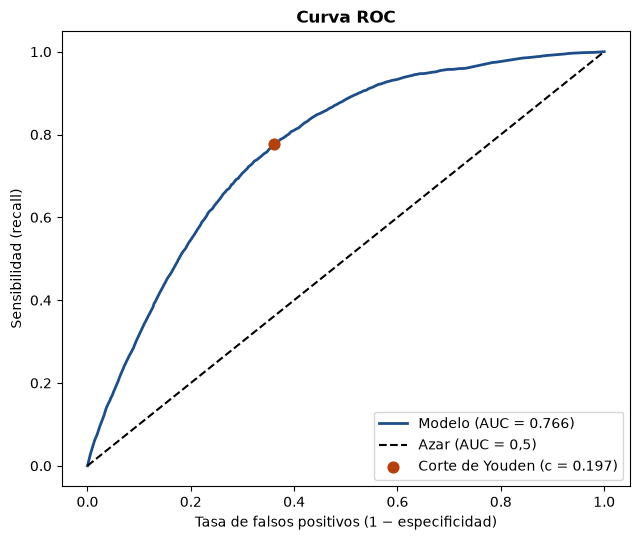

In [19]:
# ==============================================================================
# 2.6.A CURVA ROC, AUC Y PUNTO DE CORTE
# ==============================================================================
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

fpr, tpr, cortes = roc_curve(y_np, p_hat)
auc = roc_auc_score(y_np, p_hat)

# El AUC equivale al estadístico U de Mann–Whitney entre las probabilidades de ambos grupos
n1, n0 = int(y_np.sum()), int((1 - y_np).sum())
U = stats.mannwhitneyu(p_hat[y_np == 1], p_hat[y_np == 0]).statistic
Q1, Q2 = auc / (2 - auc), 2 * auc**2 / (1 + auc)
ee_auc = np.sqrt((auc * (1 - auc) + (n1 - 1) * (Q1 - auc**2) + (n0 - 1) * (Q2 - auc**2)) / (n1 * n0))
print(f"AUC = {auc:.4f} (IC 95%: {auc - 1.96 * ee_auc:.4f}–{auc + 1.96 * ee_auc:.4f}) | U/(n1·n0) = {U / (n1 * n0):.4f}")

idx_youden = np.argmax(tpr - fpr)
c_youden = cortes[idx_youden]
prevalencia = y_np.mean()

def medidas(c):
    tn, fp, fn, tp = confusion_matrix(y_np, (p_hat >= c).astype(int)).ravel()
    sens, esp = tp / (tp + fn), tn / (tn + fp)
    vpp = tp / (tp + fp) if tp + fp else np.nan
    return {"Corte": c, "VP": tp, "FP": fp, "FN": fn, "VN": tn,
            "Exactitud": (tp + tn) / (tp + tn + fp + fn),
            "Sensibilidad (recall)": sens, "Especificidad": esp,
            "VPP (precisión)": vpp, "VPN": tn / (tn + fn),
            "F1": 2 * vpp * sens / (vpp + sens), "Youden": sens + esp - 1}

tabla_cortes = pd.DataFrame({"c = 0,5": medidas(0.5), "c = prevalencia": medidas(prevalencia),
                             "c = Youden": medidas(c_youden)}).T
display(tabla_cortes.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr, tpr, color="#1D4E89", lw=2, label=f"Modelo (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0,5)")
ax.scatter(fpr[idx_youden], tpr[idx_youden], color="#B5400B", zorder=3, s=60, label=f"Corte de Youden (c = {c_youden:.3f})")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)"); ax.set_ylabel("Sensibilidad (recall)")
ax.set_title("Curva ROC", fontweight="bold"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

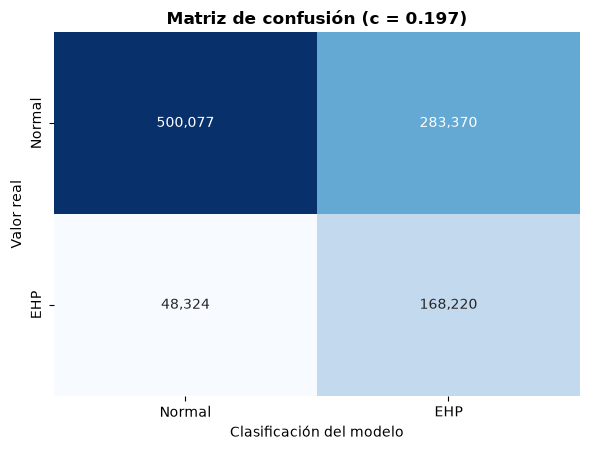

In [20]:
# ==============================================================================
# 2.6.B MATRIZ DE CONFUSIÓN CON EL CORTE DE YOUDEN
# ==============================================================================
import seaborn as sns
cm = confusion_matrix(y_np, (p_hat >= c_youden).astype(int))
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Normal", "EHP"], yticklabels=["Normal", "EHP"])
ax.set_title(f"Matriz de confusión (c = {c_youden:.3f})", fontweight="bold")
ax.set_xlabel("Clasificación del modelo"); ax.set_ylabel("Valor real")
plt.tight_layout(); plt.show()

**Interpretación: capacidad predictiva**

- **Discriminación:** el AUC es **0,766** (IC 95%: 0,765–0,767), aceptable según la guía habitual (0,7 a 0,8). Equivale al estadístico U de Mann–Whitney: si se elige al azar un egreso con EHP y otro sin EHP, el modelo asigna mayor probabilidad al que tuvo EHP en cerca de 77 de cada 100 pares.
- **Corte de 0,5:** la exactitud es 0,784, casi igual al 0,783 de predecir siempre "normal", y la sensibilidad (recall) es solo 0,150. Muestra por qué la exactitud engaña con esta prevalencia.
- **Corte de Youden ($c = 0{,}197$):** sensibilidad (recall) 0,777, especificidad 0,638, VPP (precisión) 0,373, VPN 0,912 y F1 0,504. El corte igual a la prevalencia ($c = 0{,}217$) da resultados muy similares (F1 0,504; Youden 0,411, frente a 0,415).
- **Matriz de confusión:** el modelo identifica 168.220 de los 216.544 egresos con EHP y deja pasar 48.324. A cambio, clasifica como EHP a 283.370 egresos que no la tuvieron, es decir, 1,68 falsos positivos por cada verdadero positivo.
- **Lectura:** el VPN alto indica que clasificar a un egreso como "normal" es bastante confiable, mientras que clasificarlo como EHP lo es mucho menos. El corte resume la capacidad de clasificación; el objetivo principal del estudio sigue siendo estimar y contrastar los efectos de las secciones 2.3 y 2.4.

## 3. Discusión y conclusiones

### 3.1 Relación con las hipótesis del Avance 1
Las hipótesis se contrastaron con la prueba de razón de verosimilitud por variable (sección 2.4), que compara el modelo completo con el modelo sin las indicadoras de cada variable. Además, la sección 2.4 compara cada efecto **sin ajustar** (OR crudo, comparable al análisis bivariado del Avance 1) con el efecto **ajustado** por las demás variables: si un efecto se reduce al ajustar, parte de la diferencia observada se debía a que los grupos difieren en otras características.

- **$H_{1,1}$ (edad): se confirma, con una excepción.** Se rechaza $H_{0,1}$ ($G = 26.810,8$; $q = 10$; $p < 0,001$). Ajustando por las demás variables, la chance de EHP crece desde la infancia hasta los 80 a 89 años: OR de 0,51 en 1 a 9 años, 2,02 en 60 a 69 y 2,76 (IC 95%: 2,69–2,83) en 80 a 89, frente a 30 a 39. La excepción son los **menores de un año**, con 31,0% de EHP: su OR crudo es 3,63, pero el ajustado es 0,97 (no significativo), porque su tasa alta se asocia sobre todo con su diagnóstico (afecciones perinatales). La relación no es lineal (forma de U), y por eso la edad entra al modelo por tramos: el modelo por tramos mejora al de edad lineal ($G = 1.344,0$; $q = 9$; $p < 0,001$).

- **$H_{1,2}$ (previsión; se esperaba mayor EHP en FONASA): se confirma de forma general, pero la mayor incidencia esperada en FONASA casi no se sostiene una vez ajustado.** Se rechaza $H_{0,2}$ ($G = 1.901,4$; $q = 5$; $p < 0,001$). El OR crudo de FONASA frente a ISAPRE es 3,25, pero al ajustar **solo por la red SNSS** baja a 1,09, y en el modelo completo es 1,09 (IC 95%: 1,06–1,11). La razón es que el 76,6% de los egresos FONASA se atiende en establecimientos del SNSS, frente al 1,3% de los de ISAPRE: la diferencia entre previsiones se debe casi por completo a **dónde** se atienden. El efecto de FONASA es estadísticamente significativo por el tamaño de la muestra, pero su magnitud práctica es mínima. CAPREDENA (OR 2,57), DIPRECA (2,21) y SISA (2,04) también tienen mayor chance que ISAPRE, pero son grupos pequeños (entre 5.061 y 8.597 egresos) que casi no se atienden en el SNSS, por lo que su efecto no se explica por la red y las variables disponibles no permiten determinar su causa.

- **$H_{1,3}$ (red, SNSS > No SNSS): se confirma y es el efecto más robusto.** Se rechaza $H_{0,3}$ ($G = 25.175,7$; $q = 1$; $p < 0,001$). El OR crudo es 3,73 y en el modelo completo 3,47 (IC 95%: 3,41–3,53): casi no se reduce al ajustar por edad, sexo, previsión y diagnóstico, y se mantiene al escalar por sobredispersión (3,29–3,65) y al excluir los patrones influyentes (3,42). Los datos no permiten identificar el mecanismo: la explicación del Avance 1 (presión asistencial y menor rotación de camas) es coherente con el resultado, pero también lo son una mayor complejidad clínica no medida, la derivación de los casos más graves a la red pública o la hospitalización por razones sociales.

### 3.2 Hallazgos principales

- **Aporte de cada variable.** Según la razón de verosimilitud, el diagnóstico es lo que más aporta al ajuste ($G = 48.151,8$), seguido de la edad (26.810,8) y de la red (25.175,7); la previsión (1.901,4) y el sexo (1.454,2) aportan mucho menos. Los diagnósticos con mayor chance de EHP son los trastornos mentales (OR 7,55) y las afecciones perinatales (3,75), mientras que embarazo y parto (0,36) y los factores de contacto con los servicios de salud (0,37) la reducen a menos de la mitad frente al capítulo digestivo.

- **Ajuste y desempeño.** El modelo completo es el de menor AIC y BIC ($R^2_{McF} = 0,149$). Hosmer–Lemeshow rechaza el buen ajuste ($\hat C = 3.403,7$; $p < 0,001$), algo esperable con casi un millón de egresos: la probabilidad media estimada coincide con la tasa real (0,2165) y la diferencia media por grupo de riesgo es de 1,8 puntos porcentuales. La discriminación es aceptable (AUC 0,766).

- **Qué indica el nivel de ajuste.** Un AUC cercano a 0,77 y la sobredispersión entre perfiles ($\hat\phi = 9,30$) indican que gran parte de la variación de la estadía depende de factores que no se observan en esta base, como la gravedad del cuadro, las comorbilidades o las complicaciones durante la hospitalización.

### 3.3 Coherencia con la literatura

- **Edad.** La literatura revisada en el Avance 1 no es uniforme: una mayor edad se asocia con mayor probabilidad de estadía prolongada en Hilton et al. (2020), pero no se relaciona con ella en la unidad geriátrica de pacientes de 60 años o más de Ojeda-Méndez et al. (2021). Nuestros resultados son coherentes con ambos: la chance de EHP es el doble o más desde los 60 años frente a los 30 a 39, pero entre los tramos de 60 años y más las diferencias en días son pequeñas ($|r_{rb}| \le 0,21$).
- **Determinantes institucionales.** El tipo de seguro aparece entre los predictores de la estadía en estudios internacionales (Doctoroff y Herzig, 2020; Hilton et al., 2020; Liu et al., 2024). Este estudio agrega un matiz para Chile: el efecto propio de la previsión es pequeño, porque la diferencia entre FONASA e ISAPRE casi desaparece al considerar la red donde se atiende el paciente (OR de 3,25 a 1,09), mientras que la pertenencia al SNSS mantiene un efecto robusto (OR = 3,47).
- **Vacíos del Avance 1.** Se planteó que faltaban estudios que estimaran, con datos nacionales y por episodio, la asociación ajustada entre edad, previsión y red y la estadía prolongada, y que evaluaran previsión y red en conjunto. Este estudio aborda ambos puntos con la base pública de egresos.
- **Definición de EHP y método.** El umbral del percentil 75, calculado sobre toda la base limpia (6 días), es una decisión operacional del estudio y no un estándar: la literatura usa cortes distintos, aunque coincide con el de más de 6 días de Zeleke et al. (2023). A diferencia de los estudios predictivos (Zeleke et al., 2023; Alsinglawi et al., 2024), este es un modelo estadístico: se ajusta con todos los egresos, prioriza la estimación de efectos (odds ratios) y su contraste formal, e informa la discriminación solo como complemento.

### 3.4 Sesgos y limitaciones

- **Asociación no es causalidad.** Los odds ratios describen asociaciones ajustadas, no efectos causales. Por ejemplo, el OR de la red SNSS no prueba que atenderse en el SNSS alargue la estadía: puede reflejar complejidad clínica no medida o la derivación de casos graves.
- **Independencia.** La base no tiene identificador de paciente ni de establecimiento, por lo que un mismo paciente puede aparecer en varios egresos y los egresos de un mismo hospital comparten prácticas de alta. Las observaciones no son independientes, y los intervalos de confianza pueden ser más estrechos de lo que corresponde; la sobredispersión ($\hat\phi = 9,30$) es coherente con esto. Escalar los errores por $\sqrt{\hat\phi}$ lo corrige en parte, pero no lo resuelve.
- **Un solo año y una muestra.** Se analiza una muestra aleatoria de 1.000.000 de egresos (63% de los 1.576.792 egresos limpios) de un único año (2025). Los resultados y el umbral de 6 días (percentil 75 de ese año) podrían no ser extrapolables a otros años.
- **Selección por limpieza.** Se excluyeron 128.722 egresos (7,5% de la base original): 118.961 con datos suprimidos (`*`) y 9.761 con previsión desconocida. Si esos casos difieren sistemáticamente, hay sesgo de selección.
- **Faltan variables de gravedad y comorbilidad.** No hay datos de procedimientos, complicaciones ni comorbilidades, que probablemente explican buena parte de la variación restante, y el diagnóstico se usa agrupado en 21 capítulos CIE-10, que mezclan causas con estadías muy distintas.
- **Especificación.** El modelo es aditivo, sin interacciones (por ejemplo, previsión × red).
- **Grupos pequeños.** CAPREDENA (7.226 egresos), DIPRECA (8.597), SISA (5.061) y NINGUNA (8.489), además de "Códigos especiales (U)" (851), tienen estimaciones menos precisas, y el OR de los menores de un año cambia al excluir los patrones influyentes (de 0,97 a 1,13).
- **Binarización.** Definir la EHP con un umbral descarta información de las estadías extremas (hasta 17.542 días), y el umbral es global: 6 días es prolongado para un parto y no para un accidente cerebrovascular.

### 3.5 Implicancias para la gestión de camas

- **El tipo de establecimiento y el perfil clínico concentran el riesgo.** Los egresos del SNSS, los de adultos mayores (desde 60 años) y los de ciertos capítulos (trastornos mentales, perinatales, infecciosos, piel y circulatorios) concentran la mayor probabilidad de estadía prolongada. Las intervenciones de gestión para reducir los días-cama deberían priorizar estos perfiles.
- **Comparar hospitales exige ajustar por perfil.** Dado que la diferencia entre previsiones se explica casi por completo por la red, y que la EHP varía mucho según la edad y el diagnóstico, comparar la estadía de dos establecimientos sin ajustar por edad y diagnóstico puede llevar a conclusiones erradas.
- **El efecto de la red persiste tras el ajuste.** Incluso con edad, sexo, previsión y diagnóstico controlados, atenderse en el SNSS multiplica por 3,5 la chance de EHP. Esto justifica estudiar con datos adicionales (gravedad, listas de espera, hospitalización social, tiempos de derivación) qué parte corresponde a cuellos de botella evitables en la red pública.

### 3.6 Conclusiones

1. **Respuesta a la pregunta de investigación.** Controlando por sexo y por el diagnóstico principal, la probabilidad de estadía hospitalaria prolongada ($> 6$ días) se asocia de forma significativa con la edad, la previsión y la red del establecimiento, pero con magnitudes muy distintas: la red y la edad tienen efectos grandes y estables, y la previsión, uno mínimo. En cuanto a la duración de la estadía, las pruebas del Avance 1 mostraron diferencias significativas según edad (Spearman ρ = 0,191; Kruskal–Wallis), previsión (Kruskal–Wallis) y red (Mann–Whitney U), todas con p < 0,05.
2. **Hipótesis.** Se rechazan $H_{0,1}$, $H_{0,2}$ y $H_{0,3}$. $H_{1,1}$ (edad) y $H_{1,3}$ (SNSS) se confirman, la primera con la excepción de los menores de un año. $H_{1,2}$ se confirma de forma general, pero la mayor incidencia esperada en FONASA frente a ISAPRE se explica casi por completo por la red donde se atienden (OR de 3,25 a 1,09 al ajustar por red).
3. **Modelo.** La regresión logística, estimada por máxima verosimilitud con todos los egresos, permite interpretar cada efecto mediante odds ratios y contrastar las hipótesis con la razón de verosimilitud. Su ajuste es limitado ($R^2_{McF} = 0,149$; sobredispersión), aunque sus probabilidades coinciden en promedio con la tasa real y discrimina de forma aceptable (AUC 0,766).
4. **Alcance.** Con el diagnóstico principal como condición de ingreso, el modelo describe la asociación de cada factor con la EHP, pero no permite inferir causalidad. La ausencia de variables de gravedad indica que hay un margen importante de mejora con datos clínicos adicionales.